# More efficient plants, less electricity?
## Assignment 2 · Evaluating an energy-consulting programme · Python solution

*Economic Analysis for Data Scientists, Unit 3 (Pau Milán, BSE).*

The government offered energy consulting to manufacturing plants, hoping to reduce electricity use. We evaluate the pilot with **480 plants observed for 16 months** (month −3 to 12; consulting starts in month 1). Half the plants in each sector × staffing-review cohort were randomly assigned to consulting.

**Our route** mirrors the Unit 3 practical: explore the records → describe the pattern → evaluate with the randomisation → **stop for production theory** → recover the efficiency gain → test the mechanism on held-out months → use the model for counterfactuals and advice.

| | |
|---|---|
| Language | Python 3 (pandas, numpy, matplotlib). The handout asks for R; the group confirmed Python is accepted. |
| Data | `data/energy_firms.csv`, read with a relative path. Run all cells from top to bottom. |
| Outputs | Every figure and table is also saved in `outputs/figures` and `outputs/tables`. |
| Optional work | Question 9 and the electricity-levy extension of Question 7 are included and marked *optional*. |

**Group contributions**

| Member | Thread | Questions | Main outputs |
|---|---|---|---|
| Cintia | Model and policy | Q4, Q7, Q8 (and the optional levy extension and Q9) | Theory diagrams, follow-up simulation table, policy briefing |
| Gshan | Efficiency and predictions | Q5, Q6(a), Q6(b) | Efficiency-gain estimate with CI, predicted-vs-observed plots, output-vs-electricity criterion |
| Kapil | Evaluation and firm differences | Q3, Q6(c), Q6(d), notebook assembly | Effects table and figure, heterogeneity figure, timing figure by review month; final run from a clean kernel |

Questions 1–2 and the shared model equations (§4) were done by the whole group together. All three members reviewed the briefing against their own numbers.

### Set-up and helpers
Run once. The helpers display and save figures and tables; they do not estimate anything. Colours follow the class practical.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 130, "display.max_columns", 30, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False})

DATA = "data/energy_firms.csv"
if not os.path.exists(DATA):
    raise FileNotFoundError("Open this notebook beside its data/ folder (data/energy_firms.csv).")
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

BLUE, ORANGE, GREEN, PURPLE, GREY = "#246B87", "#D77D30", "#368574", "#825493", "#737B83"
GROUP_COL = {0: BLUE, 1: ORANGE}
GROUP_LAB = {0: "Control", 1: "Consulting (treated)"}
COHORT_COL = {4: "#F2B880", 6: ORANGE, 8: "#8A3B12"}


def figure(fig, name):
    """Save the figure in outputs/figures and show it."""
    fig.tight_layout()
    fig.savefig(f"outputs/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def table_out(x, name):
    """Save the table in outputs/tables and display it."""
    x.to_csv(f"outputs/tables/{name}.csv")
    display(x)


def diff_ci(data, col):
    """Treated − control difference in plant means, with a 95% CI. Plants are the units."""
    t = data.loc[data.treated == 1, col].dropna()
    c = data.loc[data.treated == 0, col].dropna()
    d = t.mean() - c.mean()
    se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    return pd.Series({"treated": t.mean(), "control": c.mean(), "effect": d, "se": se,
                      "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se,
                      "n_treated": len(t), "n_control": len(c)})


def mean_ci(x):
    """Mean of plant-level values with a 95% CI."""
    x = pd.Series(x).dropna()
    se = x.std() / np.sqrt(len(x))
    return pd.Series({"mean": x.mean(), "ci_low": x.mean() - 1.96 * se,
                      "ci_high": x.mean() + 1.96 * se, "n_plants": len(x)})

# 1. Explore electricity use before and after consulting

## 1.1 What does one observation mean? Check the sample and the panel

One row is **one plant in one month**. Output $q$ is in standardised batches, labour $L$ in blocks of 100 paid worker-hours, electricity $E$ in MWh; all are monthly totals. Prices $p$ (CU per batch), $w$ (CU per labour block) and $c$ (CU per MWh) are plant-specific and should be constant over time.

We check: number of plants and months, duplicates, missing or non-positive values, time-invariant plant attributes, constant prices, and the randomisation design.

In [2]:
df = pd.read_csv(DATA).sort_values(["firm_id", "month"]).reset_index(drop=True)
qty = ["output", "labor", "electricity"]
prices = ["output_price", "wage", "energy_price"]
by_firm = df.groupby("firm_id")

checks = pd.Series({
    "plant-month rows": len(df),
    "plants": df.firm_id.nunique(),
    "months observed": f"{df.month.min()} to {df.month.max()} ({df.month.nunique()} months)",
    "plants with all 16 months": int((by_firm.size() == 16).sum()),
    "duplicate plant-months": int(df.duplicated(["firm_id", "month"]).sum()),
    "missing values": int(df.isna().sum().sum()),
    "non-positive quantities": int((df[qty] <= 0).sum().sum()),
    "plants whose prices change": int((by_firm[prices].nunique() > 1).any(axis=1).sum()),
    "plants whose sector/treated/adjust_month change": int(
        (by_firm[["sector", "treated", "adjust_month"]].nunique() > 1).any(axis=1).sum()),
}, name="value").to_frame()
assert checks.loc["plants", "value"] == 480 and checks.loc["duplicate plant-months", "value"] == 0
assert checks.loc["missing values", "value"] == 0 and checks.loc["plants whose prices change", "value"] == 0
table_out(checks, "01_panel_checks")

firms = df.drop_duplicates("firm_id").set_index("firm_id")
design = pd.crosstab([firms.sector, firms.adjust_month], firms.treated.map(GROUP_LAB), margins=True)
table_out(design, "01_design")

# Does labor_adjustable follow the institutional rule?
post = df[df.month >= 1]
rule_ok = (post.labor_adjustable == (post.month >= post.adjust_month)).all()
print("Months 1-12: labor_adjustable == (month >= adjust_month) for every row:", rule_ok)
print("Months -3..0: share coded labor_adjustable = 1:", df.loc[df.month <= 0, "labor_adjustable"].mean())

,value
plant-month rows,7680
plants,480
months observed,-3 to 12 (16 months)
plants with all 16 months,480
duplicate plant-months,0
missing values,0
non-positive quantities,0
plants whose prices change,0
plants whose sector/treated/adjust_month change,0


treated                 Consulting (treated)  Control  All
sector    adjust_month                                    
Chemicals 4                               40       40   80
          6                               40       40   80
          8                               40       40   80
Textiles  4                               40       40   80
          6                               40       40   80
          8                               40       40   80
All                                      240      240  480

Months 1-12: labor_adjustable == (month >= adjust_month) for every row: True
Months -3..0: share coded labor_adjustable = 1: 1.0


**What the checks show.**
- The panel is **balanced**: 480 plants × 16 months = 7,680 rows, no duplicates, no missing or non-positive quantities.
- Prices, sector, treatment and staffing cohort are **constant within each plant**, as the handout states.
- The design is exactly as described: 240 treated and 240 control plants, **40 per sector × cohort × arm**. Randomisation is stratified by sector and staffing-review month.
- `labor_adjustable` is consistent with the institutional text: it is 1 in every baseline month (all inputs free), 0 from month 1 until the review, and 1 from `adjust_month` onward (the rule `month ≥ adjust_month` holds for every row in months 1–12).
- **Points to keep in mind:** the baseline window is short (four months), quantities contain recording error, and plants differ widely in size and prices (below).

## 1.2 Who are the plants? Baseline differences and balance

We collapse the panel to **one row per plant** using window means. Averaging several months reduces the small recording errors in quantities.

| Window | Months | Why |
|---|---|---|
| Baseline | −3 to 0 | Before consulting; all inputs adjustable |
| Short run (SR) | 1 to 3 | Consulting started; labour fixed for every plant |
| Medium run (MR) | 9 to 12 | Every plant has passed its staffing review (month 4, 6 or 8) |

In [3]:
def window(a, b, var):
    return df[df.month.between(a, b)].groupby("firm_id")[var].mean()

WINDOWS = {"0": (-3, 0), "1": (1, 3), "2": (9, 12)}   # 0 = baseline, 1 = short run, 2 = medium run
P = firms[["sector", "treated", "adjust_month", "output_price", "wage", "energy_price"]].copy()
P.columns = ["sector", "treated", "adjust_month", "p", "w", "c"]
for h, (a, b) in WINDOWS.items():
    P["q" + h], P["L" + h], P["E" + h] = window(a, b, "output"), window(a, b, "labor"), window(a, b, "electricity")

# Baseline characteristics used throughout
P["labor_per_mwh0"] = P.L0 / P.E0                          # L/E: later interpreted as eta
P["energy_share0"] = P.c * P.E0 / (P.w * P.L0 + P.c * P.E0)  # electricity share of variable cost
P["profit0"] = P.p * P.q0 - P.w * P.L0 - P.c * P.E0         # operating profit, CU per month

balance_vars = {"q0": "Output (batches/month)", "L0": "Labour (100 h/month)", "E0": "Electricity (MWh/month)",
                "p": "Output price (CU/batch)", "w": "Wage (CU/block)", "c": "Electricity price (CU/MWh)",
                "labor_per_mwh0": "Labour per MWh", "energy_share0": "Electricity share of variable cost",
                "profit0": "Operating profit (CU/month)"}
bal = pd.DataFrame({lab: diff_ci(P, v) for v, lab in balance_vars.items()}).T
bal["t_stat"] = bal.effect / bal.se
bal = bal[["treated", "control", "effect", "ci_low", "ci_high", "t_stat"]]
table_out(bal.round(3), "01_baseline_balance")

by_sector = P.groupby("sector")[["q0", "L0", "E0", "c", "energy_share0", "labor_per_mwh0"]].median()
table_out(by_sector.round(3), "01_baseline_by_sector_median")

,treated,control,effect,ci_low,ci_high,t_stat
Output (batches/month),80.871,76.595,4.276,-0.043,8.594,1.941
Labour (100 h/month),174.581,161.888,12.693,0.511,24.874,2.042
Electricity (MWh/month),4413.708,4108.708,305.000,-61.202,671.203,1.632
Output price (CU/batch),23341.821,22714.275,627.545,-1679.980,2935.071,0.533
Wage (CU/block),1404.892,1415.703,-10.811,-42.085,20.463,-0.678
Electricity price (CU/MWh),162.973,163.687,-0.714,-20.864,19.436,-0.069
Labour per MWh,0.042,0.041,0.001,-0.001,0.002,0.787
Electricity share of variable cost,0.681,0.686,-0.005,-0.028,0.019,-0.391
Operating profit (CU/month),938380.278,863995.849,74384.429,-32068.600,180837.458,1.370


,q0,L0,E0,c,energy_share0,labor_per_mwh0
sector,,,,,,
Chemicals,76.771,152.487,3755.948,152.670,0.73,0.04
Textiles,73.150,153.516,3747.268,119.428,0.67,0.04


In [4]:
# Recording noise: month-to-month variation within a plant during the stable baseline
base = df[df.month <= 0]
cv = (base.groupby("firm_id")[qty].std() / base.groupby("firm_id")[qty].mean() * 100).median()
table_out(cv.rename("median within-plant CV at baseline (%)").to_frame().round(2), "01_recording_noise")

,median within-plant CV at baseline (%)
output,1.64
labor,1.22
electricity,1.77


**What the balance table shows.** Plants differ a lot: baseline electricity ranges over roughly an order of magnitude, and electricity prices vary widely across plants. Chemicals plants tend to have a higher electricity share of variable cost than textiles plants.

Treated plants are on average about 5–8% **larger** at baseline than controls. The differences are borderline (t ≈ 1.6–2.0; the labour CI just excludes zero). Randomisation makes groups comparable *in expectation*, not in every sample; size is very dispersed, so a chance gap of this kind is not surprising. Prices, labour per MWh and electricity cost shares are well balanced. Because levels differ, our comparisons below use **each plant's change relative to its own baseline**, which removes permanent plant differences.

Recording noise is small: within a plant, baseline quantities vary by about 1–2% from month to month (median coefficient of variation). Averaging over windows of 3–4 months reduces it further.

## 1.3 Electricity use before and after consulting

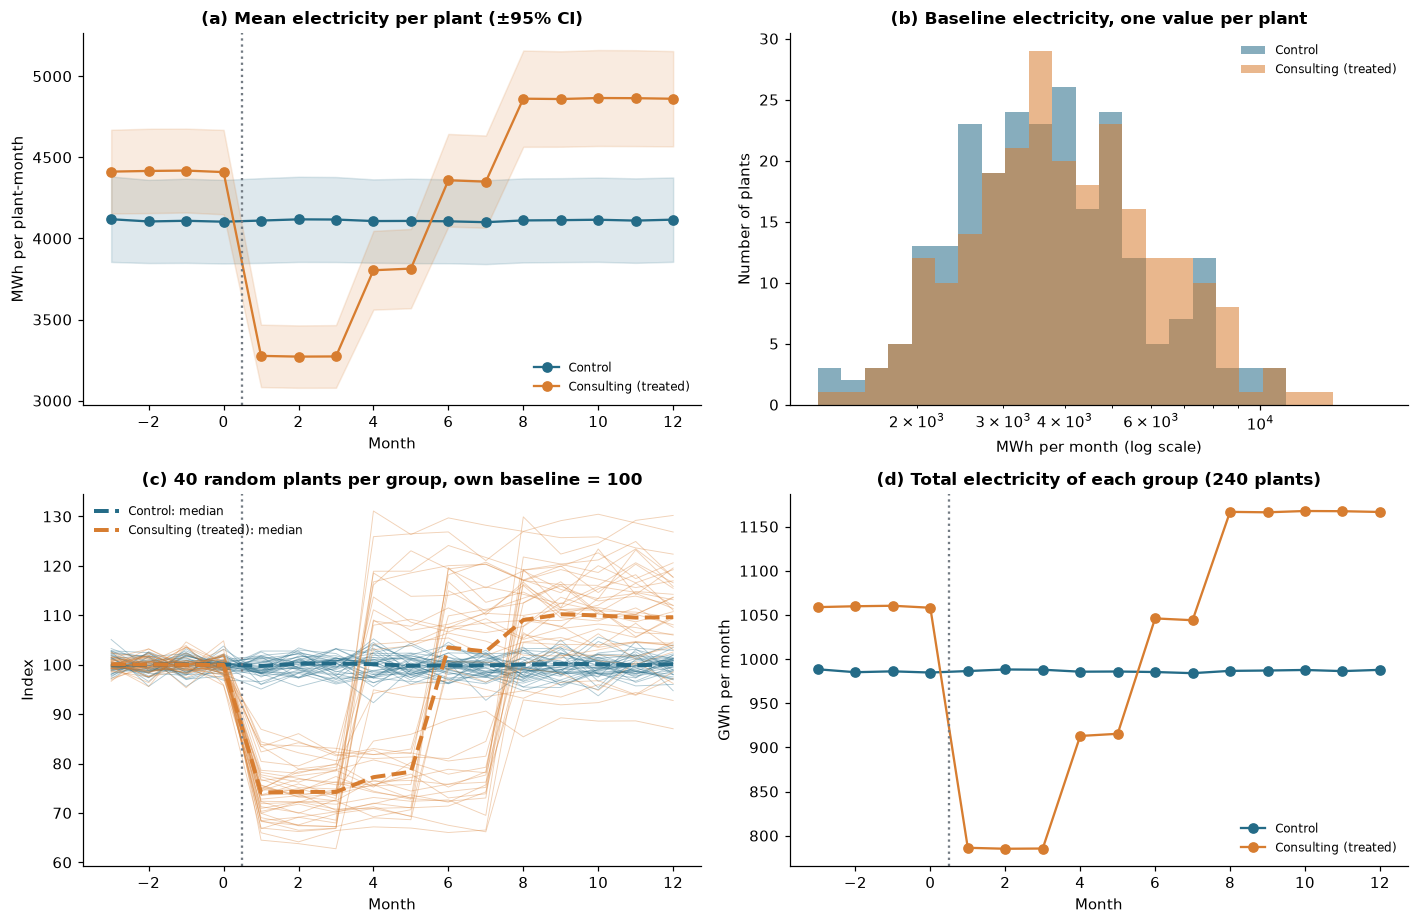

In [5]:
df = df.merge(P[["E0", "L0", "q0"]], left_on="firm_id", right_index=True)
df["e_index"] = 100 * df.electricity / df.E0          # each plant's own baseline = 100
df["dlogE"] = np.log(df.electricity / df.E0)
df["dlogL"] = np.log(df.labor / df.L0)
df["dlogq"] = np.log(df.output / df.q0)

months = np.arange(-3, 13)
rng = np.random.default_rng(7)
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))

# (a) mean electricity per plant with 95% CI
for g in (0, 1):
    s = df[df.treated == g].groupby("month").electricity
    m, se = s.mean(), s.std() / np.sqrt(s.count())
    ax[0, 0].plot(months, m, "o-", color=GROUP_COL[g], label=GROUP_LAB[g])
    ax[0, 0].fill_between(months, m - 1.96 * se, m + 1.96 * se, color=GROUP_COL[g], alpha=.15)
ax[0, 0].set(title="(a) Mean electricity per plant (±95% CI)", xlabel="Month", ylabel="MWh per plant-month")

# (b) baseline size distribution: plants are very different
bins = np.logspace(np.log10(P.E0.min()), np.log10(P.E0.max()), 25)
for g in (0, 1):
    ax[0, 1].hist(P.loc[P.treated == g, "E0"], bins=bins, alpha=.55, color=GROUP_COL[g], label=GROUP_LAB[g])
ax[0, 1].set_xscale("log")
ax[0, 1].set(title="(b) Baseline electricity, one value per plant", xlabel="MWh per month (log scale)",
             ylabel="Number of plants")

# (c) individual trajectories relative to each plant's baseline
for g in (0, 1):
    ids = rng.choice(P.index[P.treated == g], 40, replace=False)
    for i in ids:
        z = df[df.firm_id == i]
        ax[1, 0].plot(z.month, z.e_index, color=GROUP_COL[g], lw=.6, alpha=.35)
for g in (0, 1):
    ax[1, 0].plot(months, df[df.treated == g].groupby("month").e_index.median(), color=GROUP_COL[g],
                  lw=2.6, ls="--", label=f"{GROUP_LAB[g]}: median")
ax[1, 0].set(title="(c) 40 random plants per group, own baseline = 100", xlabel="Month", ylabel="Index")

# (d) totals: what the grid sees
tot = df.groupby(["month", "treated"]).electricity.sum().unstack() / 1000
for g in (0, 1):
    ax[1, 1].plot(months, tot[g], "o-", color=GROUP_COL[g], label=GROUP_LAB[g])
ax[1, 1].set(title="(d) Total electricity of each group (240 plants)", xlabel="Month", ylabel="GWh per month")

for a in ax.flat:
    if a is not ax[0, 1]:
        a.axvline(.5, ls=":", color=GREY)
    a.legend(fontsize=8)
figure(fig, "01_electricity_overview")

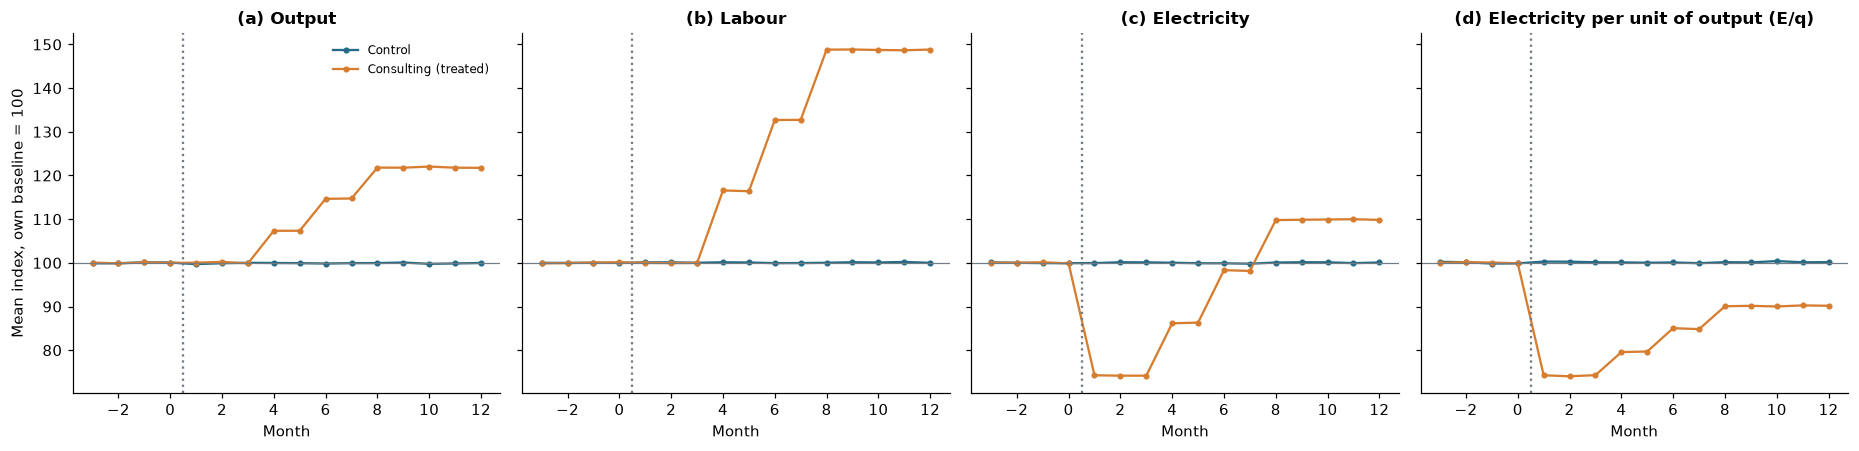

In [6]:
# Output, labour, electricity and electricity per unit of output, each plant indexed to its own baseline = 100
df["Eq_index"] = 100 * (df.electricity / df.output) / (df.E0 / df.q0)
panels = [("output", "q0", "(a) Output"), ("labor", "L0", "(b) Labour"),
          ("electricity", "E0", "(c) Electricity"), (None, None, "(d) Electricity per unit of output (E/q)")]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for a, (var, base, title) in zip(ax, panels):
    y = df.Eq_index if var is None else 100 * df[var] / df[base]
    for g in (0, 1):
        a.plot(months, y[df.treated == g].groupby(df.month).mean(), "o-", ms=3, color=GROUP_COL[g], label=GROUP_LAB[g])
    a.axhline(100, color=GREY, lw=.8)
    a.axvline(.5, ls=":", color=GREY)
    a.set(title=title, xlabel="Month")
ax[0].set_ylabel("Mean index, own baseline = 100")
ax[0].legend(fontsize=8)
figure(fig, "01_inputs_output_by_month")

**What the exploration reveals.**
- **Control plants are flat.** Their electricity use is stable through all 16 months, at both the plant level and in total. Nothing else in the environment seems to move electricity over time.
- **Treated plants drop sharply in month 1.** Mean electricity falls by roughly a quarter immediately, and the drop is visible in practically every treated trajectory, not only on average.
- **The fall does not last.** From month 4 the treated mean rises in steps; by months 8–12 treated plants use **more** electricity than at baseline.
- **Plants are heterogeneous in size** (panel b), so plant averages, proportional changes and totals can tell different stories. We keep all three in view.
- **Output and labour do not move in months 1–3** (second figure): the early fall in electricity happens with unchanged production. From month 4, treated output and labour rise in steps, to about +22% and +49% by months 9–12.
- **Electricity per unit of output falls and stays lower.** E/q drops by about 26% in month 1. It rises somewhat as plants expand, but in months 9–12 it is still about 10% below baseline. Total electricity rises because plants produce more, not because each batch needs more electricity.

This raises the question the rest of the notebook answers: **why does electricity end up higher, if the programme was meant to reduce it?** We are only describing so far; the explanation comes after the theory (§4).

# 2. What does the time pattern tell you?

A single "after" average mixes months with very different behaviour. We index each plant to its own baseline (=100) and split the treated plants by their staffing-review month (4, 6 or 8). The cohort split is legitimate: review dates were assigned before treatment and are balanced across arms.

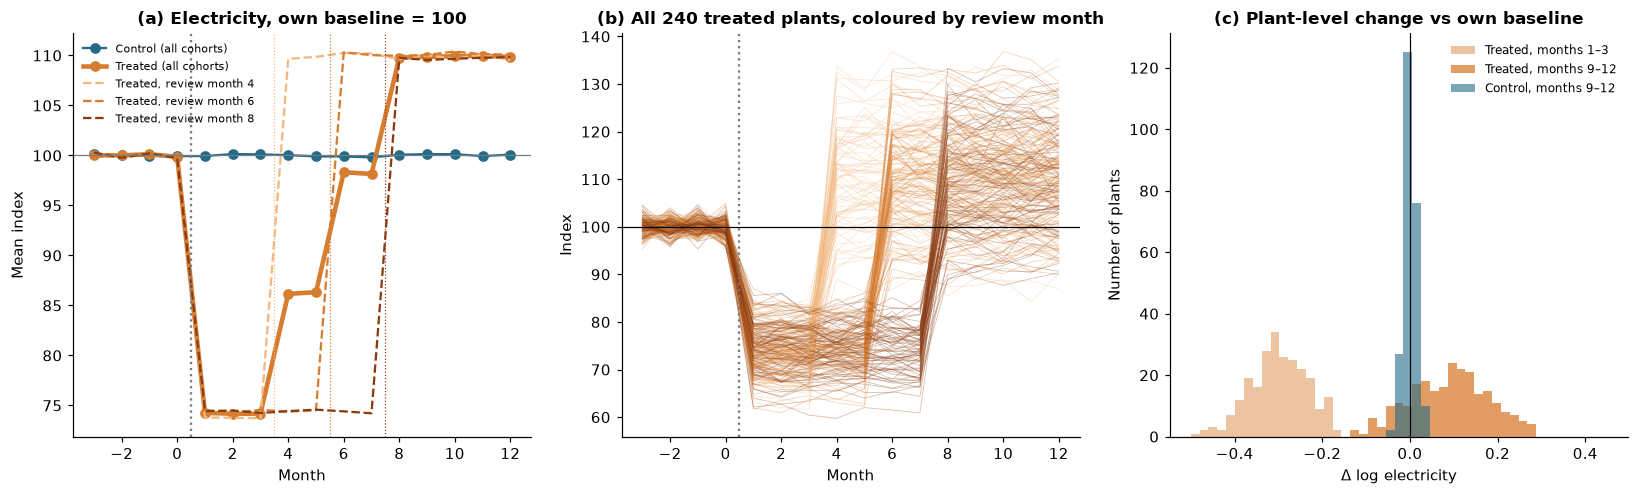

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
paths = df.groupby(["month", "treated"]).e_index.mean().unstack()
ax[0].plot(months, paths[0], "o-", color=BLUE, label="Control (all cohorts)")
ax[0].plot(months, paths[1], "o-", color=ORANGE, lw=3, label="Treated (all cohorts)")
for m, col in COHORT_COL.items():
    z = df[(df.treated == 1) & (df.adjust_month == m)].groupby("month").e_index.mean()
    ax[0].plot(z.index, z, "--", color=col, label=f"Treated, review month {m}")
    ax[0].axvline(m - .5, color=col, lw=.8, ls=":")
ax[0].axhline(100, color=GREY, lw=.8)
ax[0].set(title="(a) Electricity, own baseline = 100", xlabel="Month", ylabel="Mean index")
ax[0].legend(fontsize=7.5)

# (b) all treated plants: a common drop, then a staircase timed by the review
for i, z in df[df.treated == 1].groupby("firm_id"):
    ax[1].plot(z.month, z.e_index, color=COHORT_COL[z.adjust_month.iloc[0]], lw=.5, alpha=.35)
ax[1].axhline(100, color="black", lw=.8)
ax[1].set(title="(b) All 240 treated plants, coloured by review month", xlabel="Month", ylabel="Index")

# (c) does the average hide differences across firms?
P["dlogE_sr"] = np.log(P.E1 / P.E0)
P["dlogE_mr"] = np.log(P.E2 / P.E0)
bins = np.linspace(-.5, .45, 48)
for col, lab, alpha in [("dlogE_sr", "months 1–3", .45), ("dlogE_mr", "months 9–12", .75)]:
    ax[2].hist(P.loc[P.treated == 1, col], bins=bins, color=ORANGE, alpha=alpha, label=f"Treated, {lab}")
ax[2].hist(P.loc[P.treated == 0, "dlogE_mr"], bins=bins, color=BLUE, alpha=.6, label="Control, months 9–12")
ax[2].axvline(0, color="black", lw=.8)
ax[2].set(title="(c) Plant-level change vs own baseline", xlabel="Δ log electricity", ylabel="Number of plants")
ax[2].legend(fontsize=8)
for a in ax[:2]:
    a.axvline(.5, ls=":", color=GREY)
figure(fig, "02_time_pattern")

In [8]:
phases = {"Months 1–3 (all labour fixed)": (1, 3), "Months 4–8 (reviews take place)": (4, 8),
          "Months 9–12 (all labour free)": (9, 12), "Single post average, months 1–12": (1, 12)}
rows = {}
for lab, (a, b) in phases.items():
    # Same definition as in §3: log of the plant's window mean relative to its baseline mean
    z = np.log(window(a, b, "electricity") / P.E0).rename("dlogE").to_frame().join(P[["treated"]])
    rows[lab] = z.groupby("treated").dlogE.mean().rename(GROUP_LAB)
phase_tab = (100 * pd.DataFrame(rows).T).round(1)
phase_tab.columns = [c + ": mean Δlog E × 100" for c in phase_tab.columns]
table_out(phase_tab, "02_phases")

T = P[P.treated == 1]
het = pd.DataFrame({
    "share of treated plants below baseline, months 1–3": [(T.dlogE_sr < 0).mean()],
    "share of treated plants above baseline, months 9–12": [(T.dlogE_mr > 0).mean()],
    "treated Δlog E months 9–12: 10th pct": [T.dlogE_mr.quantile(.1)],
    "median": [T.dlogE_mr.median()],
    "90th pct": [T.dlogE_mr.quantile(.9)],
    "control Δlog E months 9–12: sd (noise benchmark)": [P.loc[P.treated == 0, "dlogE_mr"].std()],
}).T.round(3)
het.columns = ["value"]
table_out(het, "02_heterogeneity")
table_out((100 * T.groupby(["sector", "adjust_month"])[["dlogE_sr", "dlogE_mr"]].mean()).round(1),
          "02_by_sector_cohort")

,Control: mean Δlog E × 100,Consulting (treated): mean Δlog E × 100
Months 1–3 (all labour fixed),0.1,-30.0
Months 4–8 (reviews take place),-0.1,-5.3
Months 9–12 (all labour free),0.1,9.0
"Single post average, months 1–12",0.0,-5.4


,value
"share of treated plants below baseline, months 1–3",1.000
"share of treated plants above baseline, months 9–12",0.833
treated Δlog E months 9–12: 10th pct,-0.029
median,0.095
90th pct,0.207
control Δlog E months 9–12: sd (noise benchmark),0.014


dlogE_sr  dlogE_mr
sector    adjust_month                    
Chemicals 4                -30.5      10.7
          6                -30.0      12.3
          8                -29.2      10.0
Textiles  4                -30.8       7.2
          6                -29.4       6.3
          8                -30.3       7.7

**A single post-period average is not adequate.** Averaged over months 1–12, treated plants use only about 5% less electricity than at baseline (−5.4 log points, the same whole-year figure as in §3). That number averages a large saving in the first months with a later increase, and it depends on how many months happen to fall in each phase. The features that matter to a policymaker:

1. **An immediate and large fall** in month 1, shared by every treated plant (all 240 are below baseline in months 1–3).
2. **No decay while labour is fixed.** Months 1–3 are flat; the saving does not erode gradually.
3. **A step-up at the staffing review.** Each cohort's electricity jumps in exactly its review month (4, 6 or 8) and is flat afterwards. Calendar time alone does not explain the rise.
4. **A medium-run *increase***: by months 9–12 the average treated plant uses about 9% more electricity than at baseline. The horizon reverses the sign of the policy effect.
5. **Heterogeneity.** The months 9–12 change ranges widely across treated plants: most are above baseline, a minority stay below. The spread is several times the control spread, so it is not recording noise.

Controls show none of these features: their path is flat with spread consistent with recording noise.

**Sectors.** Chemicals and textiles plants are pooled above. The short-run saving is the same in both sectors (about −30 log points), but the medium-run increase is larger in chemicals (about +10 to +12) than in textiles (about +6 to +8), in every review cohort (table by sector and cohort). §6(c) asks why.

> **The pattern to explain (description, not explanation):** consulting cuts electricity immediately by roughly a quarter in every treated plant; the saving persists unchanged while labour is fixed; when a plant's staffing review allows labour to change, its electricity jumps, and in the medium run most treated plants use *more* electricity than before, by amounts that vary across plants.

# 3. Evaluate the programme

## 3.1 The comparison

**Outcome.** The stated objective is lower electricity use, so the outcome is electricity (MWh per plant-month). We report it two ways:
- the **average plant's proportional response**: mean over plants of $\Delta\log E_i = \log\bar E_i^{\text{window}}-\log\bar E_i^{\text{baseline}}$;
- the **change in total electricity**: MWh per plant-month (and summed over the 240 treated plants), and the proportional change in the treated group's total.

**Comparison.** For each plant we take the change from its own baseline (months −3 to 0) to a post window, then compare the treated and control means (a difference-in-differences on plant-level changes):
$$\hat\tau=\overline{\Delta Y}_{\text{treated}}-\overline{\Delta Y}_{\text{control}}.$$
Differencing within plants removes permanent plant differences (size, sector, prices). Subtracting the control change removes anything common to all plants over time. Because assignment is **random within sector × cohort cells**, the control change is a valid counterfactual for the treated change. With random assignment even a simple post-period comparison is unbiased; the within-plant change is more *precise* because baseline size differences are large (§1.2).

**Windows.** Short run = months 1–3 (labour fixed for everyone), medium run = months 9–12 (all reviews completed), plus the full year 1–12 for the cumulative total.

**Uncertainty.** Plants are the independent assignment units: we average each plant's months first, then compute a two-sample standard error with 240 treated and 240 control plants. Monthly observations of the same plant are not treated as independent.

In [9]:
P["dlogE_yr"] = np.log(window(1, 12, "electricity") / P.E0)
for h, (a, b) in {"sr": (1, 3), "mr": (9, 12), "yr": (1, 12)}.items():
    P["dE_" + h] = window(a, b, "electricity") - P.E0          # MWh per plant-month

labels = {"sr": "Short run (months 1–3)", "mr": "Medium run (months 9–12)", "yr": "Whole year (months 1–12)"}
eff = {}
for h, lab in labels.items():
    lg, lv = diff_ci(P, "dlogE_" + h), diff_ci(P, "dE_" + h)
    eff[lab] = {
        "Δlog E, treated": lg.treated, "Δlog E, control": lg.control,
        "Effect on log E": lg.effect, "95% CI (log)": f"[{lg.ci_low:.3f}, {lg.ci_high:.3f}]",
        "Effect, % (exp − 1)": f"{100 * np.expm1(lg.effect):.1f}%",
        "Effect, MWh per plant-month": lv.effect, "95% CI (MWh)": f"[{lv.ci_low:.0f}, {lv.ci_high:.0f}]",
        "Effect, total over 240 treated plants (MWh/month)": 240 * lv.effect,
        "N treated / control plants": f"{int(lg.n_treated)} / {int(lg.n_control)}"}
eff_tab = pd.DataFrame(eff)
eff_tab = eff_tab.apply(lambda col: col.map(lambda v: round(v, 3) if isinstance(v, float) else v))
table_out(eff_tab, "03_effects")

,Short run (months 1–3),Medium run (months 9–12),Whole year (months 1–12)
"Δlog E, treated",-0.3,0.09,-0.054
"Δlog E, control",0.001,0.001,0.0
Effect on log E,-0.301,0.09,-0.054
95% CI (log),"[-0.309, -0.293]","[0.078, 0.101]","[-0.064, -0.044]"
"Effect, % (exp − 1)",-26.0%,9.4%,-5.2%
"Effect, MWh per plant-month",-1146.326,444.151,-210.94
95% CI (MWh),"[-1222, -1070]","[374, 514]","[-259, -163]"
"Effect, total over 240 treated plants (MWh/month)",-275118.209,106596.235,-50625.598
N treated / control plants,240 / 240,240 / 240,240 / 240


In [10]:
# Proportional change in the TOTAL: ratio of group totals, with a plant bootstrap
def total_effect(Pt, Pc, col):
    return (Pt[col].sum() / Pt.E0.sum()) / (Pc[col].sum() / Pc.E0.sum()) - 1

Pt, Pc = P[P.treated == 1], P[P.treated == 0]
boot_rng = np.random.default_rng(2026)
rows = {}
for col, lab in [("E1", labels["sr"]), ("E2", labels["mr"])]:
    point = total_effect(Pt, Pc, col)
    draws = [total_effect(Pt.sample(len(Pt), replace=True, random_state=boot_rng),
                          Pc.sample(len(Pc), replace=True, random_state=boot_rng), col) for _ in range(2000)]
    avg = np.expm1(diff_ci(P, "dlogE_" + ("sr" if col == "E1" else "mr")).effect)
    rows[lab] = {"Average plant's proportional effect (%)": 100 * avg,
                 "Effect on the group TOTAL (%)": 100 * point,
                 "95% bootstrap CI, total (%)": f"[{100*np.percentile(draws, 2.5):.1f}, {100*np.percentile(draws, 97.5):.1f}]"}
table_out(pd.DataFrame(rows).T.round(1), "03_average_vs_total")

,Average plant's proportional effect (%),Effect on the group TOTAL (%),"95% bootstrap CI, total (%)"
Short run (months 1–3),-25.991,-25.944,"[-26.7, -25.2]"
Medium run (months 9–12),9.399,10.044,"[8.6, 11.5]"


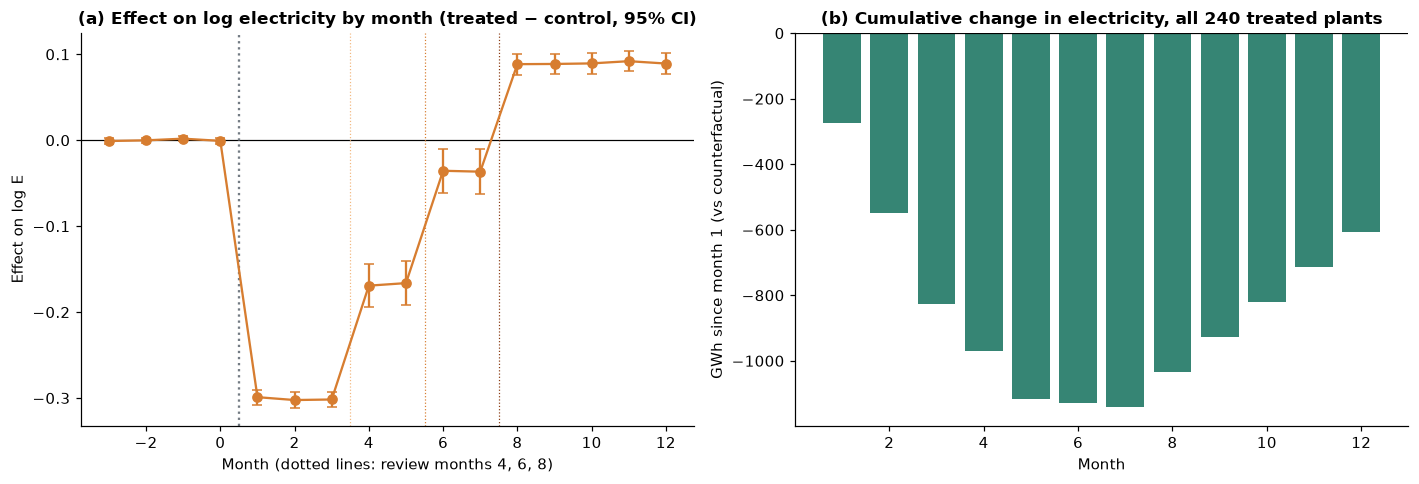

Cumulative change after 12 months: -607.5 GWh; medium-run change in total use: 106.60 GWh per month


In [11]:
# Effect by month (plants as units) and cumulative total over the year
month_eff = pd.DataFrame({m: diff_ci(df[df.month == m].set_index("firm_id").assign(
    y=lambda z: z.dlogE), "y") for m in months}).T
month_lvl = pd.DataFrame({m: diff_ci(df[df.month == m].set_index("firm_id").assign(
    y=lambda z: z.electricity - z.E0), "y") for m in months}).T
cum = (240 * month_lvl.loc[1:, "effect"]).cumsum() / 1000     # GWh, all treated plants

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].errorbar(months, month_eff.effect, yerr=1.96 * month_eff.se, fmt="o-", color=ORANGE, capsize=3)
ax[0].axhline(0, color="black", lw=.8); ax[0].axvline(.5, ls=":", color=GREY)
for m, col in COHORT_COL.items():
    ax[0].axvline(m - .5, color=col, lw=.8, ls=":")
ax[0].set(title="(a) Effect on log electricity by month (treated − control, 95% CI)",
          xlabel="Month (dotted lines: review months 4, 6, 8)", ylabel="Effect on log E")
ax[1].bar(cum.index, cum, color=[GREEN if v < 0 else ORANGE for v in cum])
ax[1].axhline(0, color="black", lw=.8)
ax[1].set(title="(b) Cumulative change in electricity, all 240 treated plants", xlabel="Month",
          ylabel="GWh since month 1 (vs counterfactual)")
figure(fig, "03_effects_by_month")
print(f"Cumulative change after 12 months: {cum.iloc[-1]:.1f} GWh; "
      f"medium-run change in total use: {240*month_lvl.loc[9:12, 'effect'].mean()/1000:.2f} GWh per month")

**Did consulting achieve its objective? It depends on the horizon.**

- **Short run (months 1–3):** consulting reduced electricity by about **26%** for the average plant (log effect ≈ −0.30, with a narrow CI). In levels, about **1,150 MWh less per plant-month**, or roughly 275 GWh less per month across the 240 treated plants. Measured against baseline levels, this is a large, precisely estimated saving.
- **Medium run (months 9–12):** the sign **reverses**. The average treated plant uses about **9% more** electricity than its counterfactual (log effect ≈ +0.09, CI excludes zero), about **+440 MWh per plant-month**.
- **Whole first year:** averaged over months 1–12 the effect is about **−5%** (log −0.054), and the cumulative saving after 12 months is about **600 GWh** across the 240 treated plants (panel b). But the cumulative balance peaks around the review months and then shrinks by about 107 GWh every month. If the medium-run effect persists at current prices, the first-year saving is used up roughly six months later (around month 18), and from then on the programme **raises** cumulative electricity use.

**Average plant vs total.** The two proportional measures are close here (−26.0% vs −25.9% in the short run; +9.4% vs +10.0% in the medium run) but are not the same object. The mean of $\Delta\log E_i$ gives every plant equal weight; the change in the group total weights plants by their electricity use. The total rises a little more in the medium run because large electricity users rebound slightly more. For energy-system or emissions goals, the **change in total MWh** is what matters; for describing a typical plant's behaviour, the average proportional response is appropriate.

Why this is informative about the **programme**, not plant differences or time: controls are flat (no common time shock), and within-plant changes remove permanent plant differences. Randomisation makes the two arms comparable, so the only systematic difference in their changes is consulting.

# STOP FOR THEORY

The evaluation tells us *what* happened. It does not tell us *why* electricity fell and then rose, or what a further programme would do. As in the power-plant practical, we now return to Unit 3: **the production function, cost minimisation, profit maximisation in two steps, fixed inputs in the short run versus the long run, and productivity and marginal cost**.

# 4. Use Unit 3 to make sense of the findings

## 4.1 The technology and the firm's problem

Plant $i$ produces
$$q=A_i\sqrt{\min\{L,\ \eta E\}}.$$
Define **energy services** $\eta E$, measured in labour-equivalent units, and the **effective input** $X=\min\{L,\eta E\}$. Labour and energy services are **perfect complements**; $\sqrt{\cdot}$ gives decreasing returns ($q$ doubles only if $X$ quadruples).

**Step 1: cost minimisation.** A profit-maximising plant never pays for an input it cannot use, so it sets $L=\eta E=X$. To produce a given output $q$ it therefore needs
$$L=\frac{q^2}{A^2},\qquad E=\frac{q^2}{A^2\,\eta}.$$
$\eta$ enters only the electricity requirement: at a given output, higher efficiency lowers $E$ and leaves $L$ unchanged. More output requires more of **both** inputs in the same proportion. Producing $X$ units of effective input costs $wX+cX/\eta$. The **price of one unit of the effective input** is
$$r=w+\frac{c}{\eta}.$$
Cost of output: $C(q)=r\,q^2/A^2$, so $MC(q)=2rq/A^2$. A rise in $\eta$ lowers $r$, so it **lowers marginal cost at every output**; it works exactly like a productivity improvement in the slides (“Productivity and marginal cost”).

**Step 2: choose output.** With $p$ given, maximise $pA\sqrt X-rX$:
$$X^*=\Big(\frac{pA}{2r}\Big)^2,\qquad q^*=\frac{pA^2}{2r},\qquad L^*=X^*,\qquad E^*=\frac{X^*}{\eta}.$$
Equivalently $p=MC(q^*)$.

The **electricity share of variable cost** is $s=\dfrac{cE}{wL+cE}=\dfrac{c/\eta}{w+c/\eta}$.

## 4.2 Short run: labour fixed (months 1 to the review month)

From month 1 paid labour is fixed at its baseline level $\bar L=X_0^*$. Labour is paid whether used or not, so within these months its cost is unavoidable and does not affect decisions. Electricity remains adjustable.

- With labour at $\bar L$, the plant can use at most $X=\bar L$. Raising $X$ beyond $\bar L$ is impossible; using less saves only electricity, at $c/\eta_1$ per unit of $X$.
- At $X=\bar L$ the marginal revenue product is $pA/(2\sqrt{\bar L})=r_0=w+c/\eta_0$, which exceeds $c/\eta_1$. So the plant **keeps output unchanged** and buys only the electricity needed to match its labour:
$$q_1=q_0,\qquad L_1=\bar L,\qquad E_1=\frac{\bar L}{\eta_1}\ \Rightarrow\ \Delta\log E_{SR}=-\Delta\log\eta.$$
The short-run saving is **purely technical**: there is no scope for a behavioural response. Operating profit rises by the electricity bill saved, $c(E_0-E_1)$.

## 4.3 Medium run: labour adjustable (after the review)

Both inputs adjust and the plant faces the lower effective price $r_1<r_0$. It expands:
$$\Delta\log X=\Delta\log q^2=2\log\frac{r_0}{r_1},\qquad \Delta\log E_{MR}=\underbrace{2\log\frac{r_0}{r_1}}_{\text{scale effect (+)}}\ \underbrace{-\ \Delta\log\eta}_{\text{technical effect (−)}}.$$
With $G=\eta_1/\eta_0$, $r_1/r_0=1-s_0+s_0/G$, so
$$\Delta\log E_{MR}=-2\log\!\left(1-s_0+\frac{s_0}{G}\right)-\log G .$$
Locally, $\dfrac{d\log E}{d\log\eta}=2s-1$. Electricity **rises** (“backfire”) when the electricity share exceeds one half; exactly, when
$$s_0>s^*(G)=\frac{\sqrt G}{1+\sqrt G}\quad(\approx 0.54\text{ for }G=1.35).$$
The factor 2 is the output elasticity of the effective input demand, $1/(1-\tfrac12)$, set by the $\sqrt{\cdot}$ returns to scale. With constant returns a plant would expand without limit; with weaker returns the scale effect is smaller.

**Which choices and constraints matter at each horizon?**

| Horizon | Fixed | Chosen | Margin | Prediction for treated plants |
|---|---|---|---|---|
| Baseline | nothing | $L,E,q$ | $p=MC$, $L=\eta_0E$ | profit-maximising scale |
| Months 1 to review | $L=\bar L$ | $E$ | use just enough $E$ to match $\bar L$ | $q,L$ unchanged; $E$ falls by $\Delta\log\eta$ |
| After review | nothing | $L,E,q$ | $p=MC$ at the lower $r_1$ | $q,L$ rise; $E$ rises if $s>s^*$ |

Controls face the same staffing rules but no change in $\eta$, so the review should change nothing for them.

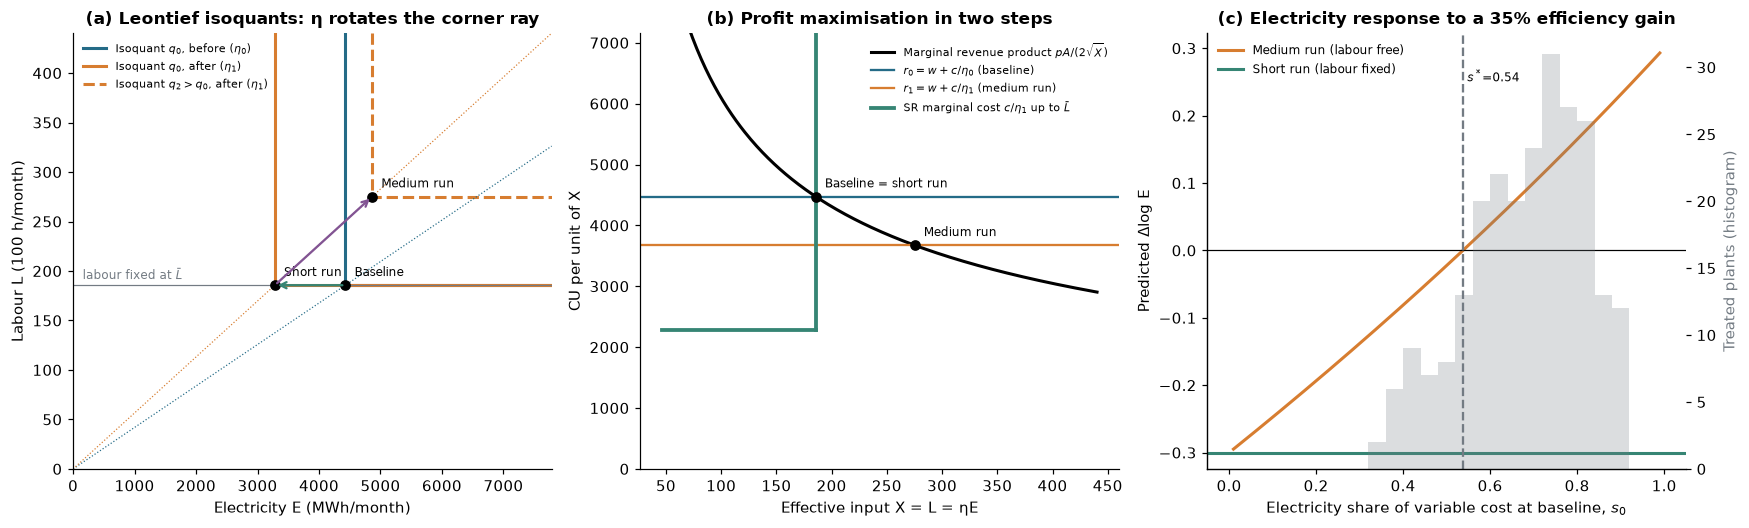

In [12]:
# Diagrams for a representative treated plant (median baseline values), using the estimated 30% log gain
rep = P[P.treated == 1].median(numeric_only=True)
A_r = rep.q0 / np.sqrt(rep.L0)
eta0_r = rep.L0 / rep.E0
G_r = np.exp(0.30)          # efficiency gain estimated in §5, used here only to draw the diagrams
eta1_r = G_r * eta0_r
r0, r1 = rep.w + rep.c / eta0_r, rep.w + rep.c / eta1_r
X0 = (rep.p * A_r / (2 * r0)) ** 2
X2 = (rep.p * A_r / (2 * r1)) ** 2
Lbar = X0

fig, ax = plt.subplots(1, 3, figsize=(16, 4.9))
# (a) isoquants in (E, L) space
Emax = 1.6 * X2 / eta1_r
def iso(a, X, eta, col, ls, lab):
    a.plot([X / eta, X / eta, Emax], [1.6 * X2, X, X], color=col, ls=ls, lw=2, label=lab)
iso(ax[0], X0, eta0_r, BLUE, "-", "Isoquant $q_0$, before ($\\eta_0$)")
iso(ax[0], X0, eta1_r, ORANGE, "-", "Isoquant $q_0$, after ($\\eta_1$)")
iso(ax[0], X2, eta1_r, ORANGE, "--", "Isoquant $q_2>q_0$, after ($\\eta_1$)")
e = np.linspace(0, Emax, 50)
ax[0].plot(e, eta0_r * e, color=BLUE, lw=.8, ls=":"); ax[0].plot(e, eta1_r * e, color=ORANGE, lw=.8, ls=":")
ax[0].axhline(Lbar, color=GREY, lw=.8)
pts = {"Baseline": (X0 / eta0_r, X0), "Short run": (Lbar / eta1_r, Lbar), "Medium run": (X2 / eta1_r, X2)}
for k, (x, y) in pts.items():
    ax[0].plot(x, y, "ko"); ax[0].annotate(k, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax[0].annotate("", xy=pts["Short run"], xytext=pts["Baseline"],
               arrowprops=dict(arrowstyle="->", color=GREEN, lw=1.5))
ax[0].annotate("", xy=pts["Medium run"], xytext=pts["Short run"],
               arrowprops=dict(arrowstyle="->", color=PURPLE, lw=1.5))
ax[0].text(Emax * .02, Lbar * 1.03, "labour fixed at $\\bar L$", fontsize=8, color=GREY)
ax[0].set(xlim=(0, Emax), ylim=(0, 1.6 * X2), xlabel="Electricity E (MWh/month)",
          ylabel="Labour L (100 h/month)", title="(a) Leontief isoquants: η rotates the corner ray")
ax[0].legend(fontsize=7.5, loc="upper left")

# (b) choosing the effective input X: MRP vs its marginal cost
X = np.linspace(X0 * .25, X2 * 1.6, 300)
ax[1].plot(X, rep.p * A_r / (2 * np.sqrt(X)), color="black", lw=2, label="Marginal revenue product $pA/(2\\sqrt{X})$")
ax[1].axhline(r0, color=BLUE, label="$r_0=w+c/\\eta_0$ (baseline)")
ax[1].axhline(r1, color=ORANGE, label="$r_1=w+c/\\eta_1$ (medium run)")
ax[1].plot([X[0], Lbar], [rep.c / eta1_r] * 2, color=GREEN, lw=2.5, label="SR marginal cost $c/\\eta_1$ up to $\\bar L$")
ax[1].plot([Lbar, Lbar], [rep.c / eta1_r, r0 * 1.6], color=GREEN, lw=2.5)
for k, (x, y) in {"Baseline = short run": (X0, r0), "Medium run": (X2, r1)}.items():
    ax[1].plot(x, y, "ko"); ax[1].annotate(k, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax[1].set(ylim=(0, r0 * 1.6), xlabel="Effective input X = L = ηE", ylabel="CU per unit of X",
          title="(b) Profit maximisation in two steps")
ax[1].legend(fontsize=7.5)

# (c) the rebound: electricity response vs energy share
s = np.linspace(0.01, .99, 200)
ax[2].plot(s, -2 * np.log(1 - s + s / G_r) - np.log(G_r), color=ORANGE, lw=2, label="Medium run (labour free)")
ax[2].axhline(-np.log(G_r), color=GREEN, lw=2, label="Short run (labour fixed)")
ax[2].axhline(0, color="black", lw=.8)
s_star = np.sqrt(G_r) / (1 + np.sqrt(G_r))
ax[2].axvline(s_star, color=GREY, ls="--"); ax[2].text(s_star + .01, .25, f"$s^*$={s_star:.2f}", fontsize=8)
a2 = ax[2].twinx()
a2.hist(P.loc[P.treated == 1, "energy_share0"], bins=25, range=(0, 1), color=GREY, alpha=.25)
a2.set_ylabel("Treated plants (histogram)", color=GREY); a2.spines["top"].set_visible(False)
ax[2].set(xlabel="Electricity share of variable cost at baseline, $s_0$", ylabel="Predicted Δlog E",
          title=f"(c) Electricity response to a {100*(G_r-1):.0f}% efficiency gain")
ax[2].legend(fontsize=8, loc="upper left")
figure(fig, "04_theory_diagrams")

*Note: the diagrams and calculations below use an efficiency gain of $G=\eta_1/\eta_0\approx1.35$ (30 log points). We estimate it in §5; we anticipate it here only to draw a realistic picture. The argument itself does not depend on its exact value.*

**Reading the diagrams.**
- **(a)** With perfect complements, cost-minimising input bundles lie on the ray $L=\eta E$. Better efficiency rotates the ray: the same output needs less electricity. In the short run labour is stuck at $\bar L$, so the plant moves **horizontally left** (green): same $L$, same $q$, less $E$. When labour is freed, it moves **out along the new ray** (purple) to a higher isoquant, using more of *both* inputs.
- **(b)** The plant buys effective input until its marginal revenue product equals its marginal cost. At baseline that cost is $r_0$. In the short run the relevant marginal cost is only $c/\eta_1$ (labour is already paid), but $X$ cannot exceed $\bar L$: the plant stays at $\bar L$. Once labour is variable, the marginal cost is $r_1<r_0$ and the plant expands to where the MRP curve meets $r_1$.
- **(c)** The short-run response is the same for every plant with the same $G$: $-\log G$. The medium-run response depends on the electricity share: plants to the right of $s^*$ end up using **more** electricity. Most treated plants lie to the right of $s^*$ (grey histogram), which is why the average medium-run effect is positive.

In [13]:
# Calculations: is baseline behaviour consistent with profit maximisation?  (uses prices, not only quantities)
P["A"] = P.q0 / np.sqrt(P.L0)                   # from q = A*sqrt(L) at baseline, with L = eta*E
P["eta0"] = P.L0 / P.E0
P["r0"] = P.w + P.c / P.eta0
P["foc_ratio"] = (P.p * P.A / (2 * np.sqrt(P.L0))) / P.r0   # = 1 if p = MC at baseline
foc = P.groupby(P.treated.map(GROUP_LAB)).foc_ratio.describe()[["count", "mean", "std", "min", "max"]]
table_out(foc.round(3), "04_baseline_foc_check")

s_star_G = np.sqrt(G_r) / (1 + np.sqrt(G_r))
calc = pd.Series({
    "Representative treated plant: s0": rep.energy_share0,
    "Assumed efficiency gain G = η1/η0 (from §5)": G_r,
    "Predicted Δlog E, short run": -np.log(G_r),
    "Predicted Δlog E, medium run": -2 * np.log(1 - rep.energy_share0 + rep.energy_share0 / G_r) - np.log(G_r),
    "Predicted Δlog q, medium run": np.log(r0 / r1),
    "Backfire threshold s*(G)": s_star_G,
    "Share of treated plants with s0 > s*": (P.loc[P.treated == 1, "energy_share0"] > s_star_G).mean(),
}, name="value").to_frame()
table_out(calc.round(3), "04_theory_calculations")

,count,mean,std,min,max
treated,,,,,
Consulting (treated),240.0,1.001,0.012,0.970,1.038
Control,240.0,1.001,0.011,0.964,1.027


,value
Representative treated plant: s0,0.702
Assumed efficiency gain G = η1/η0 (from §5),1.350
"Predicted Δlog E, short run",-0.300
"Predicted Δlog E, medium run",0.102
"Predicted Δlog q, medium run",0.197
Backfire threshold s*(G),0.537
Share of treated plants with s0 > s*,0.858


**Calculations.**
- **Baseline profit maximisation holds.** Using baseline quantities and each plant's prices, the ratio of marginal revenue product to the effective input price is $1.00$ with a standard deviation of about 1% (recording noise). This is a check with real content: it combines quantities with **prices**, which the technology alone does not restrict. It supports the assumption that plants were choosing optimally before the intervention.
- For the representative treated plant ($s_0\approx0.70$, $G\approx1.35$), the model predicts −30 log points in the short run and about +10 log points in the medium run, close to the estimated effects of −0.30 and +0.09.

**Assumptions the argument requires.**
1. The technology is Leontief in $L$ and $\eta E$ with $\sqrt{\cdot}$ returns, and $A_i$ is persistent and unaffected by consulting.
2. Plants maximise operating profit at given prices; output can be sold at $p$ without moving the price (no market-level effect; Unit 4 equilibrium is set aside).
3. Consulting changes $\eta$ once, at month 1, and the change persists.
4. Staffing commitments fix paid labour at the baseline level until the review; electricity is always free; no other variable inputs, inventories, entry or exit.
5. Plants do not waste inputs ($L=\eta E$ whenever both are chosen).

**What the account leads us to look for elsewhere in the data** (tested in §5–6):
- Treated output and labour **unchanged** in months 1–3, while $L/E$ jumps.
- After each review, treated **output and labour rise**, and electricity rises **in the same month**, proportionally to labour.
- $L/E$ stays at its new level after the review (efficiency persists).
- Stronger medium-run increases at plants with a **high baseline electricity share**.
- No change at all for controls when their review arrives.

**Assumed vs supported.** Perfect complementarity and the $\sqrt{\cdot}$ returns are **properties assumed by the technology**: with constant prices we cannot test substitution (we would need price variation). What observed behaviour can support is: unchanged output in the short run, the timing of input changes, the persistence of $L/E$, the cross-plant pattern by cost share, and the magnitude of the medium-run expansion predicted from prices.

# 5. Can the initial response reveal the efficiency gain?

## 5.1 Level versus change, and the conditions

Under the technology, a plant that wastes no inputs has $L=\eta E$, so
$$\eta=\frac{L}{E}\quad\text{(level, in labour blocks per MWh)},\qquad \Delta\log\eta=\Delta\log L-\Delta\log E\quad\text{(percentage change)}.$$
In the short run, labour is fixed and (§4.2) output is unchanged, so $\Delta\log\eta=-\Delta\log E$: **the electricity response alone reveals the efficiency gain** only if
1. labour did not change (the staffing commitment binds), and
2. output did not change (the plant stays at $X=\bar L$), so the plant is not simply producing less.

If output had fallen, part of the electricity fall would be a scale reduction, not efficiency. We check both conditions, and use the control plants to remove anything common to all plants. We average months to reduce recording noise: baseline = months −3 to 0, short run = months 1–3.

In [14]:
P["eta1"] = P.L1 / P.E1
P["eta2"] = P.L2 / P.E2
P["dlogq_sr"], P["dlogL_sr"] = np.log(P.q1 / P.q0), np.log(P.L1 / P.L0)
P["dlogeta_sr"] = np.log(P.eta1 / P.eta0)
P["dlogeta_mr"] = np.log(P.eta2 / P.eta0)

cond = pd.DataFrame({
    "Δlog output": diff_ci(P, "dlogq_sr"), "Δlog labour": diff_ci(P, "dlogL_sr"),
    "Δlog electricity": diff_ci(P, "dlogE_sr"), "Δlog η = Δlog(L/E)": diff_ci(P, "dlogeta_sr")}).T
table_out(cond[["treated", "control", "effect", "ci_low", "ci_high"]].round(4), "05_short_run_conditions")

g_eff = diff_ci(P, "dlogeta_sr")
noise_sd = P.loc[P.treated == 0, "dlogeta_sr"].std()
treat_sd = P.loc[P.treated == 1, "dlogeta_sr"].std()
eta_tab = pd.Series({
    "Mean baseline η, all plants (labour blocks per MWh)": P.eta0.mean(),
    "  = worker-hours per MWh": 100 * P.eta0.mean(),
    "Effect on log η (treated − control)": g_eff.effect,
    "95% CI, log": f"[{g_eff.ci_low:.3f}, {g_eff.ci_high:.3f}]",
    "Implied efficiency increase (%)": f"{100*np.expm1(g_eff.effect):.1f}% [{100*np.expm1(g_eff.ci_low):.1f}, {100*np.expm1(g_eff.ci_high):.1f}]",
    "SD of plant Δlog η, treated": treat_sd,
    "SD of plant Δlog η, control (= noise)": noise_sd,
    "Implied SD of true gains across treated plants": np.sqrt(treat_sd**2 - noise_sd**2),
}, name="value").to_frame()
table_out(eta_tab.map(lambda v: round(v, 4) if isinstance(v, float) else v), "05_efficiency_gain")

,treated,control,effect,ci_low,ci_high
Δlog output,3.000e-04,-1.400e-03,0.002,-9.000e-04,4.200e-03
Δlog labour,-4.000e-04,7.000e-04,-0.001,-3.200e-03,9.000e-04
Δlog electricity,-3.005e-01,5.000e-04,-0.301,-3.093e-01,-2.926e-01
Δlog η = Δlog(L/E),3.001e-01,2.000e-04,0.300,2.912e-01,3.085e-01


,value
"Mean baseline η, all plants (labour blocks per MWh)",0.042
= worker-hours per MWh,4.156
Effect on log η (treated − control),0.3
"95% CI, log","[0.291, 0.309]"
Implied efficiency increase (%),"35.0% [33.8, 36.1]"
"SD of plant Δlog η, treated",0.066
"SD of plant Δlog η, control (= noise)",0.019
Implied SD of true gains across treated plants,0.063


**The conditions hold.** In months 1–3, treated plants' output and labour change by essentially zero relative to controls (effects of a fraction of a percent, CIs around zero), while electricity falls by 0.30 log points. The electricity response is therefore informative about efficiency:

- **Level.** At baseline $\eta_0=L/E\approx0.042$ labour blocks per MWh (about 4.2 paid worker-hours per MWh of electricity). The level varies across plants; it is what makes labour and electricity comparable in the model, but the programme's effect is a *change*.
- **Change attributable to consulting.** The treated − control difference in $\Delta\log(L/E)$ is **≈ 0.30 (about +35% efficiency)** with a tight CI. Controls show no change in $\eta$, so there is no common trend to remove, but the comparison guarantees that.
- **Heterogeneity.** The control spread in $\Delta\log\eta$ measures recording noise after averaging. The treated spread is much larger, so true gains vary across plants (roughly 0.15 to 0.48 log points). Plant-level estimates are noisy; group averages are precise.

## 5.2 Does the efficiency gain persist?

Once labour can change, electricity alone no longer reveals $\eta$: it now mixes the technical and the scale effects. But the model still says $\eta=L/E$ **whenever both inputs are chosen**. So we compare $L/E$ in months 9–12 with $L/E$ in months 1–3. This relies on the Leontief/no-waste assumption: with a technology that allows substitution, $L/E$ would also reflect relative prices and would not measure $\eta$ (§9).

,treated,control,effect,ci_low,ci_high
"Δlog η, months 1–3 vs baseline",3.001e-01,2.000e-04,2.999e-01,0.291,0.308
"Δlog η, months 9–12 vs baseline",3.000e-01,5.000e-04,2.995e-01,0.291,0.308
"Δlog η, months 9–12 vs months 1–3",-1.000e-04,2.000e-04,-3.000e-04,-0.004,0.003


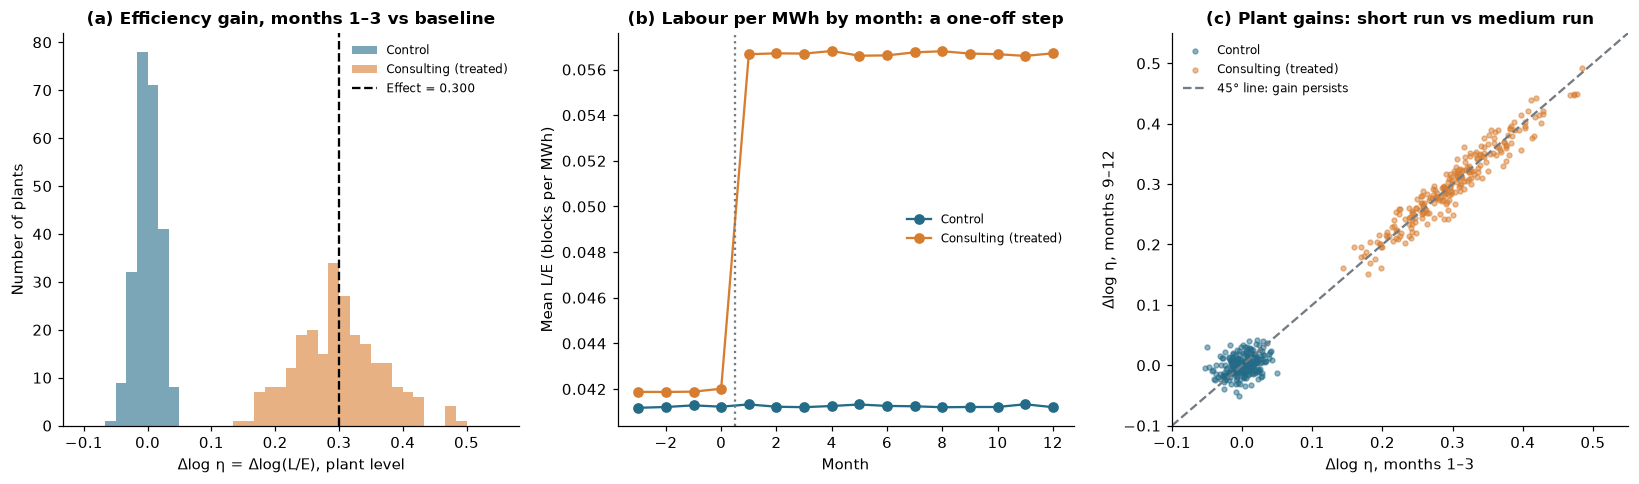

In [15]:
P["dlogeta_sr_to_mr"] = np.log(P.eta2 / P.eta1)
persist = pd.DataFrame({"Δlog η, months 1–3 vs baseline": diff_ci(P, "dlogeta_sr"),
                        "Δlog η, months 9–12 vs baseline": diff_ci(P, "dlogeta_mr"),
                        "Δlog η, months 9–12 vs months 1–3": diff_ci(P, "dlogeta_sr_to_mr")}).T
table_out(persist[["treated", "control", "effect", "ci_low", "ci_high"]].round(4), "05_persistence")

df["eta_ratio"] = df.labor / df.electricity
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
bins = np.linspace(-.1, .55, 40)
for g in (0, 1):
    ax[0].hist(P.loc[P.treated == g, "dlogeta_sr"], bins=bins, color=GROUP_COL[g], alpha=.6, label=GROUP_LAB[g])
ax[0].axvline(g_eff.effect, color="black", ls="--", label=f"Effect = {g_eff.effect:.3f}")
ax[0].set(title="(a) Efficiency gain, months 1–3 vs baseline", xlabel="Δlog η = Δlog(L/E), plant level",
          ylabel="Number of plants"); ax[0].legend(fontsize=8)
for g in (0, 1):
    z = df[df.treated == g].groupby("month").eta_ratio
    ax[1].plot(months, z.mean(), "o-", color=GROUP_COL[g], label=GROUP_LAB[g])
ax[1].axvline(.5, ls=":", color=GREY)
ax[1].set(title="(b) Labour per MWh by month: a one-off step", xlabel="Month", ylabel="Mean L/E (blocks per MWh)")
ax[1].legend(fontsize=8)
for g in (0, 1):
    z = P[P.treated == g]
    ax[2].scatter(z.dlogeta_sr, z.dlogeta_mr, s=10, alpha=.5, color=GROUP_COL[g], label=GROUP_LAB[g])
lim = [-.1, .55]
ax[2].plot(lim, lim, color=GREY, ls="--", label="45° line: gain persists")
ax[2].set(xlim=lim, ylim=lim, title="(c) Plant gains: short run vs medium run",
          xlabel="Δlog η, months 1–3", ylabel="Δlog η, months 9–12"); ax[2].legend(fontsize=8)
figure(fig, "05_efficiency_gain")

**The efficiency change persists.** Labour per MWh steps up in month 1 and then stays flat for the rest of the year, including after the staffing reviews (panel b). Plant by plant, the medium-run gain lines up with the short-run gain along the 45° line (panel c); the average change between months 1–3 and 9–12 is close to zero. So the later rise in electricity is **not** the consulting effect wearing off: the plants remain more efficient while using more electricity.

**What depends on the technology.** The short-run estimate needs only that output and labour did not move and that electricity is used in fixed proportion to energy services, which the data support. Reading $L/E$ as $\eta$ in the medium run depends on perfect complementarity and no waste; under a technology with substitution the same ratio would also move with scale or prices.

# 6. Does your explanation predict more than the initial pattern?

## 6(a) The magnitude of later choices: out-of-sample prediction

We recover every plant parameter from **baseline and months 1–3 only**, then predict months 9–12 **before** looking at them:
- $A_i=q_{i0}/\sqrt{L_{i0}}$ (baseline),
- $\eta_{i1}=L_{i1}/E_{i1}$ (months 1–3; for controls this equals their baseline $\eta$ up to noise),
- prices $p_i,w_i,c_i$ (constant).

Prediction: $X^*=\big(pA/2r_1\big)^2$, $q^*=A\sqrt{X^*}$, $L^*=X^*$, $E^*=X^*/\eta_1$, operating profit $\pi^*=pq^*-wL^*-cE^*$.

In [16]:
# --- Prediction step: uses only baseline and months 1-3 ---
P["r1"] = P.w + P.c / P.eta1
P["X_pred"] = (P.p * P.A / (2 * P.r1)) ** 2
P["q_pred"] = P.A * np.sqrt(P.X_pred)
P["L_pred"] = P.X_pred
P["E_pred"] = P.X_pred / P.eta1
P["profit_pred"] = P.p * P.q_pred - P.w * P.L_pred - P.c * P.E_pred
P[["q_pred", "L_pred", "E_pred", "profit_pred"]].to_csv("outputs/tables/06a_predictions_made_before_months_9_12.csv")

baseline mean  predicted mean  observed mean  mean log error  RMSE (log)  \
Output           Control                      76.595       7.669e+01      7.652e+01          -0.002       0.024   
                 Consulting (treated)         80.871       9.872e+01      9.876e+01           0.000       0.024   
Labour           Control                     161.888       1.623e+02      1.620e+02          -0.001       0.029   
                 Consulting (treated)        174.581       2.608e+02      2.604e+02          -0.001       0.028   
Electricity      Control                    4108.708       4.120e+03      4.113e+03          -0.001       0.022   
                 Consulting (treated)       4413.708       4.870e+03      4.862e+03          -0.001       0.023   
Operating profit Control                  863995.849       8.642e+05      8.601e+05          -0.003       0.030   
                 Consulting (treated)     938380.278       1.166e+06      1.168e+06           0.001       0.030   

                                       corr(log obs, log pred)  
Output           Control                                 0.997  
                 Consulting (treated)                    0.997  
Labour           Control                                 0.997  
                 Consulting (treated)                    0.998  
Electricity      Control                                 0.999  
                 Consulting (treated)                    0.999  
Operating profit Control                                 0.999  
                 Consulting (treated)                    0.999

,value
"corr(observed, predicted) Δlog E, treated",0.970
"corr(observed, predicted) Δlog q, treated",0.918
"mean predicted Δlog E, treated",0.091
"mean observed Δlog E, treated",0.090


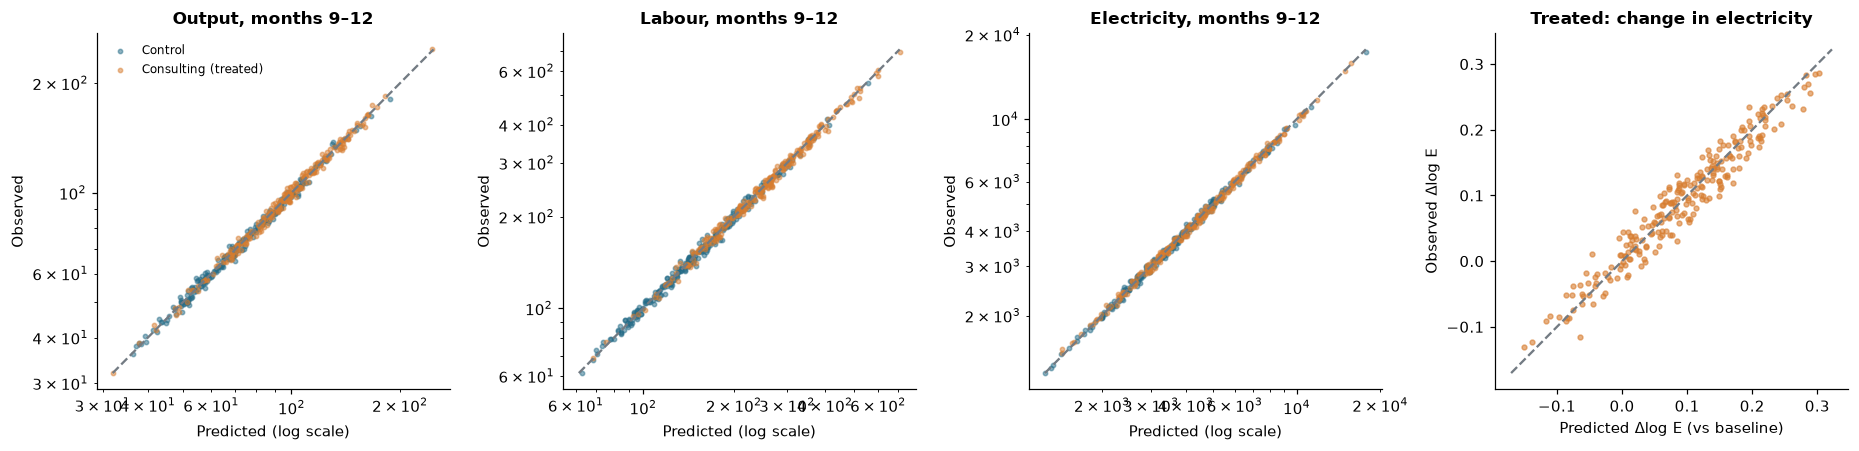

In [17]:
# --- Comparison step: now bring in the held-out months 9-12 ---
P["profit2"] = P.p * P.q2 - P.w * P.L2 - P.c * P.E2
rows = {}
for v, obs, pred in [("Output", "q2", "q_pred"), ("Labour", "L2", "L_pred"),
                     ("Electricity", "E2", "E_pred"), ("Operating profit", "profit2", "profit_pred")]:
    for g in (0, 1):
        z = P[P.treated == g]
        err = np.log(z[obs] / z[pred])
        rows[(v, GROUP_LAB[g])] = {
            "baseline mean": z[obs.replace("2", "0")].mean() if v != "Operating profit" else z.profit0.mean(),
            "predicted mean": z[pred].mean(), "observed mean": z[obs].mean(),
            "mean log error": err.mean(), "RMSE (log)": np.sqrt((err**2).mean()),
            "corr(log obs, log pred)": np.corrcoef(np.log(z[obs]), np.log(z[pred]))[0, 1]}
fit = pd.DataFrame(rows).T
table_out(fit.round(3), "06a_prediction_fit")

# Does the model predict the CHANGE, not just the level? (levels are dominated by plant size)
P["dlogq_mr"] = np.log(P.q2 / P.q0)
P["dlogL_mr"] = np.log(P.L2 / P.L0)
P["dlogE_mr_pred"] = np.log(P.E_pred / P.E0)
P["dlogq_mr_pred"] = np.log(P.q_pred / P.q0)
T = P[P.treated == 1]
chg = pd.Series({"corr(observed, predicted) Δlog E, treated": np.corrcoef(T.dlogE_mr, T.dlogE_mr_pred)[0, 1],
                 "corr(observed, predicted) Δlog q, treated": np.corrcoef(T.dlogq_mr, T.dlogq_mr_pred)[0, 1],
                 "mean predicted Δlog E, treated": T.dlogE_mr_pred.mean(),
                 "mean observed Δlog E, treated": T.dlogE_mr.mean()}, name="value").to_frame()
table_out(chg.round(3), "06a_change_fit")

fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
for a, (v, obs, pred) in zip(ax[:3], [("Output", "q2", "q_pred"), ("Labour", "L2", "L_pred"), ("Electricity", "E2", "E_pred")]):
    for g in (0, 1):
        z = P[P.treated == g]
        a.scatter(z[pred], z[obs], s=8, alpha=.5, color=GROUP_COL[g], label=GROUP_LAB[g])
    lo, hi = P[[obs, pred]].min().min(), P[[obs, pred]].max().max()
    a.plot([lo, hi], [lo, hi], color=GREY, ls="--")
    a.set(xscale="log", yscale="log", title=f"{v}, months 9–12", xlabel="Predicted (log scale)", ylabel="Observed")
ax[0].legend(fontsize=8)
ax[3].scatter(T.dlogE_mr_pred, T.dlogE_mr, s=10, alpha=.6, color=ORANGE)
lim = [T[["dlogE_mr", "dlogE_mr_pred"]].min().min() - .02, T[["dlogE_mr", "dlogE_mr_pred"]].max().max() + .02]
ax[3].plot(lim, lim, color=GREY, ls="--")
ax[3].set(title="Treated: change in electricity", xlabel="Predicted Δlog E (vs baseline)", ylabel="Observed Δlog E")
figure(fig, "06a_out_of_sample")

In [18]:
# Discrepancies: are errors systematic?
T = P[P.treated == 1].copy()
T["err_E"] = np.log(T.E2 / T.E_pred)
T["share_bin"] = pd.qcut(T.energy_share0, 4, labels=["Q1 low s", "Q2", "Q3", "Q4 high s"])
disc = pd.concat({"by sector": T.groupby("sector").err_E.agg(["mean", "std", "count"]),
                  "by review month": T.groupby("adjust_month").err_E.agg(["mean", "std", "count"]),
                  "by electricity share": T.groupby("share_bin", observed=True).err_E.agg(["mean", "std", "count"])})
table_out(disc.round(4), "06a_discrepancies")
worst = T.reindex(T.err_E.abs().sort_values(ascending=False).index)[
    ["sector", "adjust_month", "energy_share0", "dlogeta_sr", "E_pred", "E2", "err_E"]].head(5)
table_out(worst.round(3), "06a_largest_errors")

mean    std  count
by sector            Chemicals -1.500e-03  0.024    120
                     Textiles  -1.000e-04  0.022    120
by review month      4          2.000e-04  0.019     80
                     6         -3.000e-04  0.025     80
                     8         -2.200e-03  0.024     80
by electricity share Q1 low s   7.000e-04  0.022     60
                     Q2         1.500e-03  0.025     60
                     Q3        -1.600e-03  0.023     60
                     Q4 high s -3.600e-03  0.021     60

,sector,adjust_month,energy_share0,dlogeta_sr,E_pred,E2,err_E
firm_id,,,,,,,
F372,Chemicals,6,0.562,0.244,2061.175,2180.997,0.057
F089,Textiles,6,0.617,0.289,1442.278,1526.061,0.056
F068,Textiles,4,0.621,0.277,4366.004,4132.081,-0.055
F414,Chemicals,8,0.416,0.397,3099.991,2945.568,-0.051
F389,Chemicals,6,0.724,0.288,4025.522,3826.313,-0.051


**Profit maximisation predicts later choices accurately.** Using only months −3 to 3, the model predicts months 9–12 output, labour, electricity and profit with log errors centred on zero and an RMSE of about 2–3%, the size of the recording noise. More demanding than fitting levels (which are dominated by plant size), it predicts the **change**: for treated plants, predicted and observed $\Delta\log E$ are highly correlated, and the mean predicted rise matches the observed one. Controls are predicted to stay where they are, and they do.

**Discrepancies.** Errors show no systematic pattern by sector, review cohort or electricity share. The largest individual errors are a few percent and are consistent with noise in the plant-specific $\eta_1$ estimate (three months of data) entering the prediction. Small biases would be a warning sign: a positive error at high $s$ would suggest substitution or an omitted variable input; none is visible.

This is a **genuine out-of-sample test**: nothing from months 4–12 entered the parameters. It tests jointly the technology, the persistence of $\eta$, profit maximisation and the absence of other changes ($A$, prices).

## 6(b) Production and electricity: is the output change large enough?

From $q=A\sqrt{\eta E}$ when inputs are balanced, between baseline and the medium run
$$\Delta\log E_{MR}=2\,\Delta\log q_{MR}-\Delta\log\eta .$$
**Criterion.** With $\Delta\log\eta$ estimated from months 1–3, electricity rises above baseline **if and only if** $\Delta\log q_{MR}>\tfrac12\Delta\log\eta_{SR}$: output must grow by more than half the (log) efficiency gain. A positive output response alone is not enough. Quantitatively, the predicted electricity change from the output change should match the observed one.

,value
treated plants meeting Δlog q > ½Δlog η,199.000
treated plants with E above baseline in months 9–12,200.000
agreement between the two classifications,0.921
"corr(2Δlog q − Δlog η_SR, observed Δlog E)",0.937
mean gap: observed − implied Δlog E,-0.001


col_0,does not,meets criterion,All
sector,,,
Chemicals,13,107,120
Textiles,28,92,120
All,41,199,240


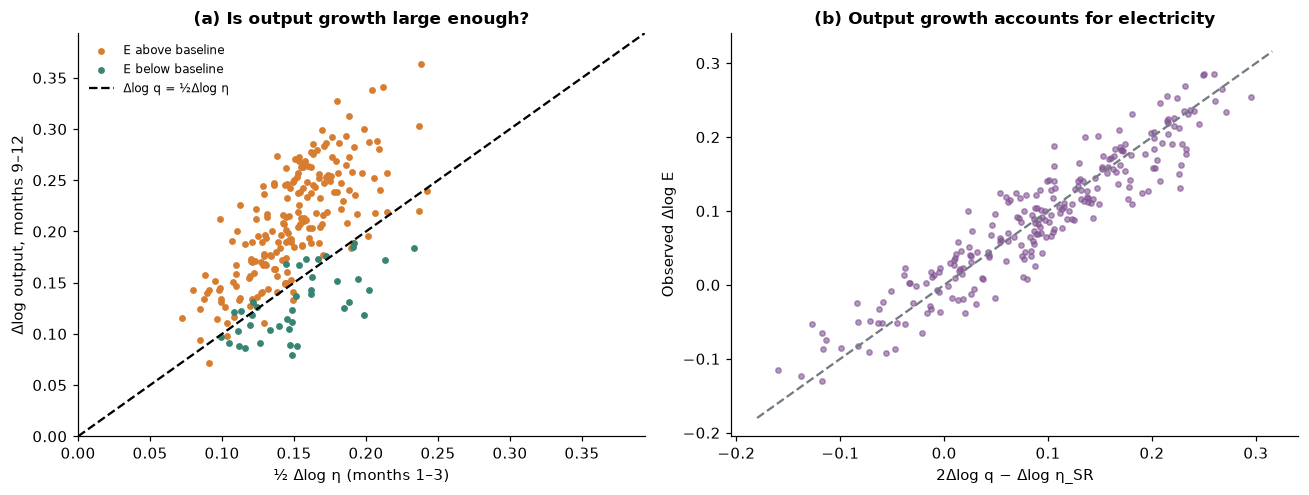

In [19]:
P["half_gain"] = .5 * P.dlogeta_sr
P["dlogE_from_q"] = 2 * P.dlogq_mr - P.dlogeta_sr
T = P[P.treated == 1]
crit = pd.Series({
    "treated plants meeting Δlog q > ½Δlog η": int((T.dlogq_mr > T.half_gain).sum()),
    "treated plants with E above baseline in months 9–12": int((T.dlogE_mr > 0).sum()),
    "agreement between the two classifications": (np.sign(T.dlogq_mr - T.half_gain) == np.sign(T.dlogE_mr)).mean(),
    "corr(2Δlog q − Δlog η_SR, observed Δlog E)": np.corrcoef(T.dlogE_from_q, T.dlogE_mr)[0, 1],
    "mean gap: observed − implied Δlog E": (T.dlogE_mr - T.dlogE_from_q).mean(),
}, name="value").to_frame()
table_out(crit.round(3), "06b_criterion")
table_out(pd.crosstab(T.sector, T.dlogq_mr > T.half_gain, margins=True).rename(
    columns={True: "meets criterion", False: "does not"}), "06b_criterion_by_sector")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
up = T.dlogE_mr > 0
ax[0].scatter(T.half_gain[up], T.dlogq_mr[up], s=12, color=ORANGE, label="E above baseline")
ax[0].scatter(T.half_gain[~up], T.dlogq_mr[~up], s=12, color=GREEN, label="E below baseline")
lim = [0, T[["half_gain", "dlogq_mr"]].max().max() + .03]
ax[0].plot(lim, lim, color="black", ls="--", label="Δlog q = ½Δlog η")
ax[0].set(xlim=lim, ylim=lim, xlabel="½ Δlog η (months 1–3)", ylabel="Δlog output, months 9–12",
          title="(a) Is output growth large enough?"); ax[0].legend(fontsize=8)
ax[1].scatter(T.dlogE_from_q, T.dlogE_mr, s=12, color=PURPLE, alpha=.6)
lim = [T[["dlogE_from_q", "dlogE_mr"]].min().min() - .02, T[["dlogE_from_q", "dlogE_mr"]].max().max() + .02]
ax[1].plot(lim, lim, color=GREY, ls="--")
ax[1].set(xlabel="2Δlog q − Δlog η_SR", ylabel="Observed Δlog E", title="(b) Output growth accounts for electricity")
figure(fig, "06b_output_vs_electricity")

**Yes, the output expansion is large enough.** Plants above the diagonal in (a) expanded output by more than half their efficiency gain, and these are largely the plants whose electricity rose above baseline (199 meet the criterion, 200 are above baseline; the two classifications agree for 92% of plants, with mismatches close to the line where recording noise decides). Panel (b) shows that the electricity change implied by the output change and the short-run efficiency gain matches the observed change plant by plant, with no systematic gap.

**Prediction or identity?** Be careful here. Once $\eta$ is measured in the *same* window ($\eta_{MR}=L_2/E_2$) and $q=A\sqrt L$, the relation $2\Delta\log q-\Delta\log\eta=\Delta\log E$ is an **accounting identity** of the technology and proves nothing. Using $\eta$ from **months 1–3** makes it a test: it holds only if the efficiency gain persisted, if no extra $A$ change occurred, and if output still requires labour and energy services in the same proportions. The criterion classifies plants; the out-of-sample prediction in 6(a) is the stronger evidence because it does not use months 9–12 quantities at all.

## 6(c) Differences across firms: who responds most?

From §4.3, $\Delta\log E_{MR}=-2\log(1-s_0+s_0/G)-\log G$. Two sources of heterogeneity:
- **Size of the improvement** $G$: a property of what consulting achieved at the plant (estimated from months 1–3).
- **Response to a given improvement**, governed by the **pre-intervention electricity share** $s_0=cE_0/(wL_0+cE_0)$: the more electricity matters for costs, the more a given efficiency gain lowers the effective input price, and the bigger the expansion.

Prediction: holding $G$ fixed, plants with a **high baseline electricity share** (energy-intensive plants, with high $c$ or low $\eta_0$) should show the **strongest later electricity increase**. A larger $G$ raises the medium-run response only where $s_0>\tfrac12$ (since $d\log E/d\log\eta=2s-1$).

,s0,gain,dlogE_mr,dlogE_pred,share_above_baseline,plants
share_bin,,,,,,
Q1 (lowest s0),0.496,0.302,-0.025,-0.025,0.333,60
Q2,0.645,0.302,0.064,0.063,1.000,60
Q3,0.746,0.290,0.128,0.129,1.000,60
Q4 (highest s0),0.836,0.307,0.195,0.198,1.000,60


,coef,robust se
constant,-0.023,0.002
s0 − 0.5,0.627,0.009
g − mean(g),-0.167,0.021
(s0 − 0.5)×(g − mean g),1.978,0.126


corr(s0, g) among treated plants: 0.015 | control plants' s0 vs medium-run Δlog E: 0.023


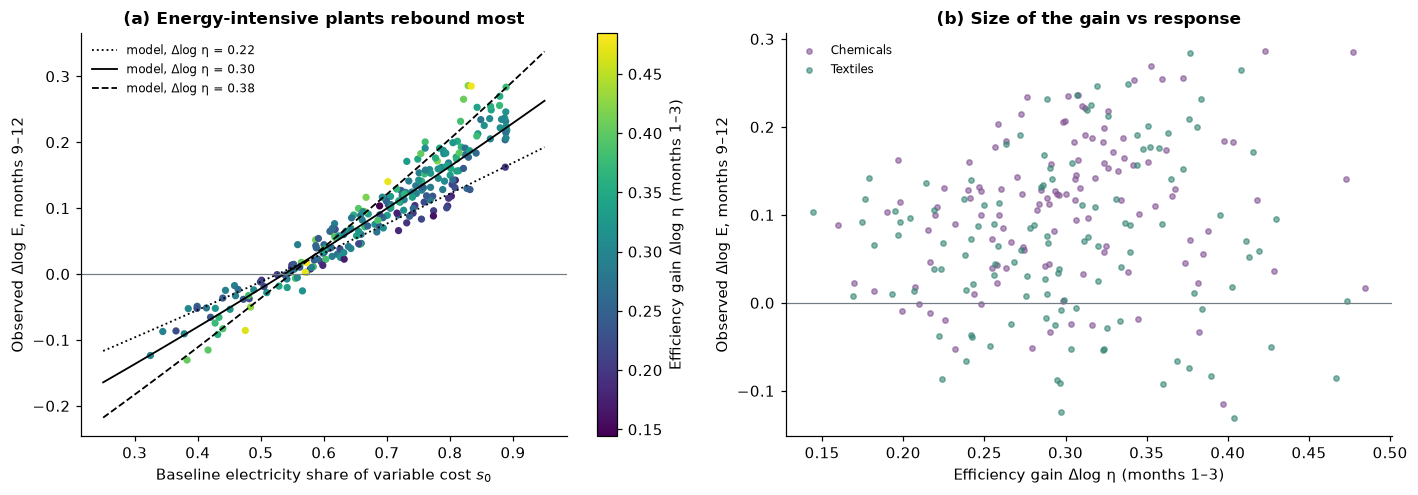

In [20]:
T = P[P.treated == 1].copy()
T["g"] = T.dlogeta_sr
T["share_bin"] = pd.qcut(T.energy_share0, 4, labels=["Q1 (lowest s0)", "Q2", "Q3", "Q4 (highest s0)"])
qt = T.groupby("share_bin", observed=True).agg(
    s0=("energy_share0", "mean"), gain=("g", "mean"),
    dlogE_mr=("dlogE_mr", "mean"), dlogE_pred=("dlogE_mr_pred", "mean"),
    share_above_baseline=("dlogE_mr", lambda x: (x > 0).mean()), plants=("g", "size"))
table_out(qt.round(3), "06c_by_energy_share")

# OLS: observed medium-run change on s0 and g (plants as observations, robust SEs)
Xm = np.column_stack([np.ones(len(T)), T.energy_share0 - .5, T.g - T.g.mean(), (T.energy_share0 - .5) * (T.g - T.g.mean())])
y = T.dlogE_mr.values
beta = np.linalg.lstsq(Xm, y, rcond=None)[0]
u = y - Xm @ beta
XtXi = np.linalg.inv(Xm.T @ Xm)
se = np.sqrt(np.diag(XtXi @ (Xm.T * u**2) @ Xm @ XtXi))
reg = pd.DataFrame({"coef": beta, "robust se": se}, index=["constant", "s0 − 0.5", "g − mean(g)", "(s0 − 0.5)×(g − mean g)"])
table_out(reg.round(3), "06c_regression")
print("corr(s0, g) among treated plants:", round(np.corrcoef(T.energy_share0, T.g)[0, 1], 3),
      "| control plants' s0 vs medium-run Δlog E:",
      round(np.corrcoef(P.loc[P.treated == 0, "energy_share0"], P.loc[P.treated == 0, "dlogE_mr"])[0, 1], 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sc = ax[0].scatter(T.energy_share0, T.dlogE_mr, c=T.g, cmap="viridis", s=14)
plt.colorbar(sc, ax=ax[0], label="Efficiency gain Δlog η (months 1–3)")
s = np.linspace(.25, .95, 100)
for gq, ls in zip(T.g.quantile([.1, .5, .9]), [":", "-", "--"]):
    G = np.exp(gq)
    ax[0].plot(s, -2 * np.log(1 - s + s / G) - np.log(G), color="black", ls=ls, lw=1.2, label=f"model, Δlog η = {gq:.2f}")
ax[0].axhline(0, color=GREY, lw=.8)
ax[0].set(xlabel="Baseline electricity share of variable cost $s_0$", ylabel="Observed Δlog E, months 9–12",
          title="(a) Energy-intensive plants rebound most"); ax[0].legend(fontsize=8)
for sec, col in [("Chemicals", PURPLE), ("Textiles", GREEN)]:
    z = T[T.sector == sec]
    ax[1].scatter(z.g, z.dlogE_mr, s=12, color=col, alpha=.6, label=sec)
ax[1].axhline(0, color=GREY, lw=.8)
ax[1].set(xlabel="Efficiency gain Δlog η (months 1–3)", ylabel="Observed Δlog E, months 9–12",
          title="(b) Size of the gain vs response"); ax[1].legend(fontsize=8)
figure(fig, "06c_heterogeneity")

**Energy-intensive plants show the strongest rebound.** Moving from the lowest to the highest quartile of baseline electricity share, the medium-run electricity change rises steadily, from close to zero or negative to well above baseline, as the model predicts (the observed and predicted columns agree). The regression confirms a large positive coefficient on $s_0$ and a positive interaction: a bigger efficiency gain raises electricity **more** where $s_0$ is high, as $2s-1$ implies.

**Size of the improvement vs response to it.** The estimated gains $G$ are essentially uncorrelated with $s_0$, so the two sources of heterogeneity are separate. Plants with large gains do not systematically rebound more unless they are also energy-intensive; panel (b) shows only a weak raw relationship between $g$ and the medium-run response. Chemicals plants have higher electricity shares on average, so they rebound more, *not* because consulting worked differently there (the average gain is the same in both sectors). For controls, $s_0$ does not predict any change, so the pattern is not a pre-existing trend among energy-intensive plants.

## 6(d) Input relationships and timing

With perfect complements and a constant $\eta$ after month 1:
- **Months 1–3 → 9–12:** $\eta$ does not change, so $\Delta\log E=\Delta\log L$: slope 1, intercept 0.
- **Baseline → 9–12:** $\Delta\log E=\Delta\log L-\Delta\log\eta$: slope 1, but shifted down by each plant's efficiency gain (about −0.30).
- **Timing:** labour can change only from the review month, so treated plants' labour, output and electricity should all jump **in the review month**, and not before. Controls should not change at their review.

,slope,intercept,corr
Months 1–3 → 9–12: Δlog E on Δlog L,0.998,0.001,0.988
Baseline → 9–12: Δlog E on Δlog L,0.643,-0.161,0.834
Baseline → 9–12: (Δlog E + Δlog η_SR) on Δlog L,1.003,-0.001,0.988


labor_adjustable,labour fixed (before review),labour adjustable
treated,,
Control,0.013,0.013
Consulting (treated),0.013,0.391


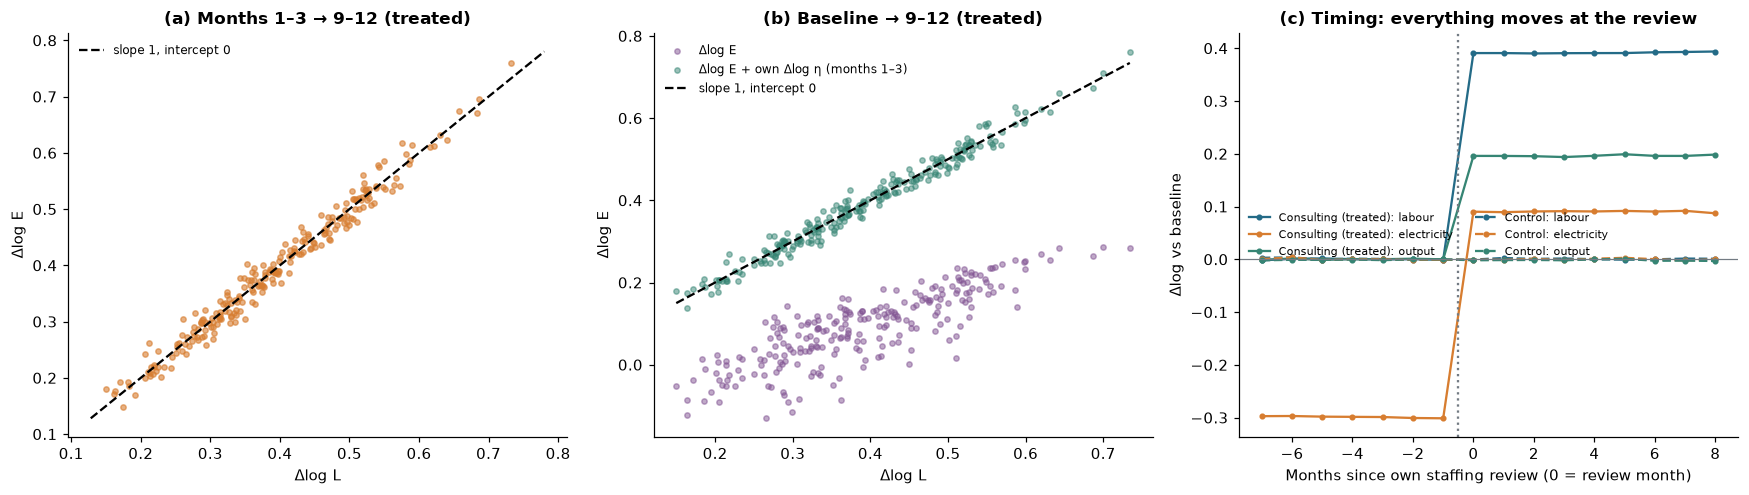

In [21]:
P["dlogL_srmr"] = np.log(P.L2 / P.L1)
P["dlogE_srmr"] = np.log(P.E2 / P.E1)
T = P[P.treated == 1]

def ols_line(x, y):
    b = np.polyfit(x, y, 1)
    return pd.Series({"slope": b[0], "intercept": b[1], "corr": np.corrcoef(x, y)[0, 1]})
rel = pd.DataFrame({"Months 1–3 → 9–12: Δlog E on Δlog L": ols_line(T.dlogL_srmr, T.dlogE_srmr),
                    "Baseline → 9–12: Δlog E on Δlog L": ols_line(T.dlogL_mr, T.dlogE_mr),
                    "Baseline → 9–12: (Δlog E + Δlog η_SR) on Δlog L": ols_line(T.dlogL_mr, T.dlogE_mr + T.dlogeta_sr)}).T
table_out(rel.round(3), "06d_input_relationships")

# Event time relative to the review month
df["event"] = df.month - df.adjust_month
ev = df[df.month >= 1].groupby(["treated", "event"])[["dlogL", "dlogE", "dlogq"]].mean()

# Labour moves only when allowed
lab = df[df.month.between(1, 12)].assign(abs_dlogL=lambda z: z.dlogL.abs()).groupby(
    ["treated", "labor_adjustable"]).abs_dlogL.mean().unstack().rename(index=GROUP_LAB,
    columns={0: "labour fixed (before review)", 1: "labour adjustable"})
table_out(lab.round(4), "06d_labour_when_adjustable")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].scatter(T.dlogL_srmr, T.dlogE_srmr, s=12, color=ORANGE, alpha=.6)
lim = [min(T.dlogL_srmr.min(), T.dlogE_srmr.min()) - .02, max(T.dlogL_srmr.max(), T.dlogE_srmr.max()) + .02]
ax[0].plot(lim, lim, color="black", ls="--", label="slope 1, intercept 0")
ax[0].set(xlabel="Δlog L", ylabel="Δlog E", title="(a) Months 1–3 → 9–12 (treated)"); ax[0].legend(fontsize=8)
ax[1].scatter(T.dlogL_mr, T.dlogE_mr, s=12, color=PURPLE, alpha=.5, label="Δlog E")
ax[1].scatter(T.dlogL_mr, T.dlogE_mr + T.dlogeta_sr, s=12, color=GREEN, alpha=.5, label="Δlog E + own Δlog η (months 1–3)")
x = np.linspace(T.dlogL_mr.min(), T.dlogL_mr.max(), 10)
ax[1].plot(x, x, color="black", ls="--", label="slope 1, intercept 0")
ax[1].set(xlabel="Δlog L", ylabel="Δlog E", title="(b) Baseline → 9–12 (treated)"); ax[1].legend(fontsize=8)
for g, ls in [(1, "-"), (0, "--")]:
    z = ev.loc[g]
    ax[2].plot(z.index, z.dlogL, ls, marker="o", ms=3, color=BLUE, label=f"{GROUP_LAB[g]}: labour")
    ax[2].plot(z.index, z.dlogE, ls, marker="o", ms=3, color=ORANGE, label=f"{GROUP_LAB[g]}: electricity")
    ax[2].plot(z.index, z.dlogq, ls, marker="o", ms=3, color=GREEN, label=f"{GROUP_LAB[g]}: output")
ax[2].axvline(-.5, color=GREY, ls=":")
ax[2].axhline(0, color=GREY, lw=.8)
ax[2].set(xlabel="Months since own staffing review (0 = review month)", ylabel="Δlog vs baseline",
          title="(c) Timing: everything moves at the review"); ax[2].legend(fontsize=7, ncol=2, loc="center left")
figure(fig, "06d_inputs_timing")

**Input relationships.** Between the short and medium run, labour and electricity change one-for-one (slope ≈ 1, intercept ≈ 0): efficiency is constant, and the plants scale both inputs together. Compared with baseline, the raw slope is well below 1 (≈ 0.64) and the line is shifted down. The model explains why: $\Delta\log E=\Delta\log L-\Delta\log\eta_i$, and the efficiency gain differs across plants. Plants with larger gains expand labour more *and* save more electricity per worker, which flattens the raw slope. Adding back each plant's own short-run gain restores a slope of about 1 with intercept about 0 (third row; green points in b). For the same labour increase, electricity rises about 30 log points less than it would have without consulting. The comparison window matters: relative to baseline the relationship mixes the one-off technical change with the scale change; relative to months 1–3 it isolates the scale change.

**Timing.** Aligning plants by their own review month, labour, output and electricity of treated plants are flat until the review and jump **in the review month**, then stay flat. Labour essentially never moves while it is contractually fixed. Controls do not react to their review at all: they were already at their optimum. This rules out explanations tied to calendar time (seasonality, learning, gradual decay) because the jump happens at different calendar months for different cohorts.

**What each piece of evidence establishes.**

| Evidence | Type | What it establishes |
|---|---|---|
| Short-run $q,L$ unchanged, $E$ falls (§5) | Test of SR prediction | The fall is technical, not a scale reduction |
| $L/E$ constant after month 1 (§5.2) | Test, given Leontief | Efficiency gain persists; no decay |
| Months 9–12 predicted from months −3…3 (6a) | **Out-of-sample prediction** | Profit maximisation at the lower effective price explains the size of the expansion |
| $2\Delta\log q-\Delta\log\eta_{SR}$ vs $\Delta\log E$ (6b) | Test across windows; identity if $\eta$ from same window | Output growth is large enough to explain the rebound |
| Rebound increasing in $s_0$ (6c) | Test of a cross-sectional prediction | The mechanism runs through the cost of energy services |
| Slopes ≈ 1 (6d) | Largely implied by Leontief + persistence | Inputs move together |
| Jumps at the review month only (6d) | Test of timing | Labour constraint is the binding margin |

**An alternative explanation: the consultants' advice fades (or plants become careless).** If the efficiency gain decayed, electricity would rise with **unchanged output and labour**, $L/E$ would fall back towards baseline, and the rise would be gradual in calendar time. We see instead output and labour rising, $L/E$ constant, and discrete jumps exactly at plant-specific review months. A second alternative, **consulting also raised general productivity $A$** (e.g. better management), would raise output with $L/E$ unchanged; but it would also have raised output in months 1–3 when labour was fixed ($q=A\sqrt{\bar L}$), which did not happen, and our prediction with baseline $A$ already fits months 9–12. A third, **demand shocks**, is ruled out by randomisation, constant prices and flat controls.

**Limits of the evidence.** Prices never vary, so we cannot test substitution between labour and electricity directly; the Leontief form is maintained. The data are synthetic and cover only 12 months, with no capital, entry, exit or market-price effects. We do not observe what consulting cost, environmental damages, or whether output price would fall if many plants expanded (a Unit 4 equilibrium effect).

# 7. Evaluate a further efficiency improvement

A follow-up programme would raise each treated plant's current efficiency by 20%: $\eta_{2}=1.2\,\eta_{i1}$, with $A_i$ and prices unchanged.

**Common baseline (no follow-up):** the model's medium-run optimum at $\eta_{i1}$ (§6a), i.e. $X^*_1=(pA/2r_1)^2$. Using the model rather than the noisy observations keeps all three scenarios on exactly the same footing.

| Scenario | Labour | Electricity | Output |
|---|---|---|---|
| Fixed labour | $\bar L=X_1^*$ | $\bar L/\eta_2$ | unchanged |
| Free labour | $X_2^*=(pA/2r_2)^2$, $r_2=w+c/\eta_2$ | $X_2^*/\eta_2$ | $A\sqrt{X_2^*}$ |

Operating profit $=pq-wL-cE$, **excluding** the unknown cost of delivering consulting.

,No follow-up,"Follow-up, labour fixed","Follow-up, labour free",Δ% fixed labour,Δ% free labour
Output (batches/month),2.369e+04,2.369e+04,2.648e+04,0.0,11.8
Labour (100 h/month),6.259e+04,6.259e+04,7.839e+04,0.0,25.2
Electricity (MWh/month),1.169e+06,9.741e+05,1.221e+06,-16.7,4.4
Operating profit (CU/month),2.799e+08,3.121e+08,3.164e+08,11.5,13.0


,value
plants whose electricity rises (free labour),181.000
plants whose electricity falls (free labour),59.000
Δlog E free labour: 10th pct,-0.045
median,0.043
90th pct,0.101
"mean electricity share before original programme, s0",0.681
"mean electricity share now, s1",0.619
share of plants with s1 > s*(1.2),0.754


,dlogE_fixed (×100 log pts),dlogE_free (×100 log pts),dlogq_free (×100 log pts)
sector,,,
Chemicals,-18.2,4.9,11.6
Textiles,-18.2,2.3,10.3


Original MR effect 0.090 log points for a 0.300 log gain.
Naive proportional extrapolation to a 20% gain: 0.055; model prediction (mean plant): 0.036


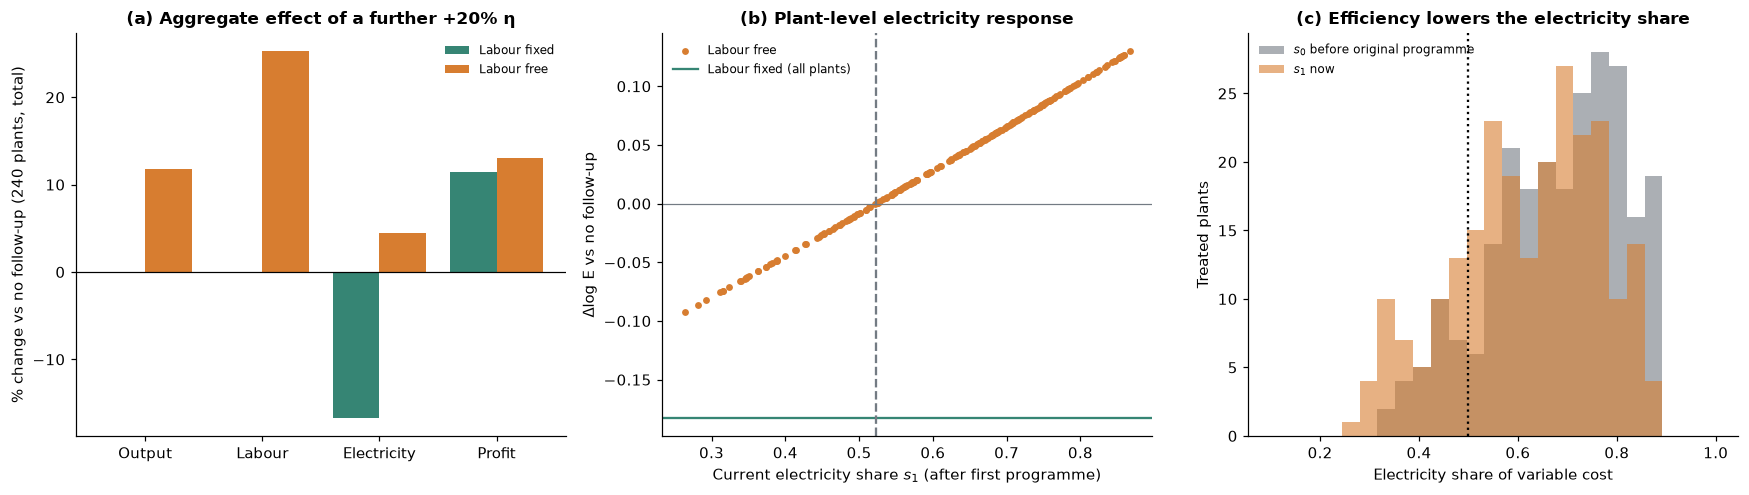

In [22]:
T = P[P.treated == 1].copy()
T["eta_fu"] = 1.2 * T.eta1

def outcome(Tdf, X, eta, label):
    q, L, E = Tdf.A * np.sqrt(X), X, X / eta
    return pd.DataFrame({"q": q, "L": L, "E": E, "profit": Tdf.p * q - Tdf.w * L - Tdf.c * E}).assign(scenario=label)

X_base = (T.p * T.A / (2 * (T.w + T.c / T.eta1))) ** 2
X_free = (T.p * T.A / (2 * (T.w + T.c / T.eta_fu))) ** 2
sc_base = outcome(T, X_base, T.eta1, "No follow-up")
sc_fix = outcome(T, X_base, T.eta_fu, "Follow-up, labour fixed")
sc_free = outcome(T, X_free, T.eta_fu, "Follow-up, labour free")

agg = pd.DataFrame({s.scenario.iloc[0]: s[["q", "L", "E", "profit"]].sum() for s in [sc_base, sc_fix, sc_free]})
agg.index = ["Output (batches/month)", "Labour (100 h/month)", "Electricity (MWh/month)", "Operating profit (CU/month)"]
agg["Δ% fixed labour"] = 100 * (agg.iloc[:, 1] / agg.iloc[:, 0] - 1)
agg["Δ% free labour"] = 100 * (agg.iloc[:, 2] / agg.iloc[:, 0] - 1)
table_out(agg.round(1), "07_follow_up_aggregate")

plant = pd.DataFrame({"dlogE_fixed": np.log(sc_fix.E / sc_base.E), "dlogE_free": np.log(sc_free.E / sc_base.E),
                      "dlogq_free": np.log(sc_free.q / sc_base.q),
                      "s1": T.c / T.eta1 / (T.w + T.c / T.eta1), "s0": T.energy_share0, "sector": T.sector})
het7 = pd.Series({
    "plants whose electricity rises (free labour)": int((plant.dlogE_free > 0).sum()),
    "plants whose electricity falls (free labour)": int((plant.dlogE_free <= 0).sum()),
    "Δlog E free labour: 10th pct": plant.dlogE_free.quantile(.1),
    "median": plant.dlogE_free.median(), "90th pct": plant.dlogE_free.quantile(.9),
    "mean electricity share before original programme, s0": plant.s0.mean(),
    "mean electricity share now, s1": plant.s1.mean(),
    "share of plants with s1 > s*(1.2)": (plant.s1 > np.sqrt(1.2) / (1 + np.sqrt(1.2))).mean(),
}, name="value").to_frame()
table_out(het7.round(3), "07_follow_up_heterogeneity")
table_out((100 * plant.groupby("sector")[["dlogE_fixed", "dlogE_free", "dlogq_free"]].mean()).round(1).add_suffix(" (×100 log pts)"),
          "07_follow_up_by_sector")

# Naive extrapolation of the original effect vs the model
orig_mr = diff_ci(P, "dlogE_mr").effect
naive = orig_mr * np.log(1.2) / g_eff.effect
print(f"Original MR effect {orig_mr:.3f} log points for a {g_eff.effect:.3f} log gain."
      f"\nNaive proportional extrapolation to a 20% gain: {naive:.3f}; model prediction (mean plant): {plant.dlogE_free.mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
x = np.arange(4)
ax[0].bar(x - .2, agg["Δ% fixed labour"], .4, color=GREEN, label="Labour fixed")
ax[0].bar(x + .2, agg["Δ% free labour"], .4, color=ORANGE, label="Labour free")
ax[0].set_xticks(x, ["Output", "Labour", "Electricity", "Profit"]); ax[0].axhline(0, color="black", lw=.8)
ax[0].set(ylabel="% change vs no follow-up (240 plants, total)", title="(a) Aggregate effect of a further +20% η")
ax[0].legend(fontsize=8)
ax[1].scatter(plant.s1, plant.dlogE_free, s=12, color=ORANGE, label="Labour free")
ax[1].axhline(np.log(1 / 1.2), color=GREEN, label="Labour fixed (all plants)")
ax[1].axhline(0, color=GREY, lw=.8); ax[1].axvline(np.sqrt(1.2) / (1 + np.sqrt(1.2)), color=GREY, ls="--")
ax[1].set(xlabel="Current electricity share $s_1$ (after first programme)", ylabel="Δlog E vs no follow-up",
          title="(b) Plant-level electricity response"); ax[1].legend(fontsize=8)
ax[2].hist(plant.s0, bins=25, range=(0.1, 1), color=GREY, alpha=.6, label="$s_0$ before original programme")
ax[2].hist(plant.s1, bins=25, range=(0.1, 1), color=ORANGE, alpha=.6, label="$s_1$ now")
ax[2].axvline(.5, color="black", ls=":")
ax[2].set(xlabel="Electricity share of variable cost", ylabel="Treated plants",
          title="(c) Efficiency lowers the electricity share"); ax[2].legend(fontsize=8)
figure(fig, "07_follow_up")

**Predictions.**
- **Labour fixed at the current medium-run level:** output and labour are unchanged and every plant's electricity falls by exactly $\log(1/1.2)$, i.e. **−16.7%**. Profits rise by the electricity bill saved. This is the short-run logic of §4.2 again.
- **Labour free:** plants expand output (+12%) and labour (+25%), and total electricity **rises by about 4%** instead of falling. 181 of 240 plants increase electricity; energy-intensive plants (high $s_1$) increase it most, the least energy-intensive reduce it. Profits rise more than with fixed labour because the plant can re-optimise (envelope logic: more choice cannot lower profit).

**Why extrapolating the original effect is misleading.** The response of electricity to efficiency is $2s-1$, and **$s$ falls as $\eta$ rises** (panel c): the first programme already cut the electricity share from about 0.68 to about 0.6. A further gain therefore produces a smaller scale effect relative to the technical saving. Scaling the original medium-run effect (+0.090 log points for a 0.30 gain) in proportion to the new gain ($\log1.2=0.18$) would predict +0.055; the model predicts +0.036 for the average plant. The naive rule ignores the falling share, and also ignores that the relationship is non-linear in $G$, that it differs by plant ($s_i$ varies), and that the sign depends on the horizon (fixed vs free labour). The original percentage effect is not a structural constant; the model's parameters are.

## 7 (optional extension): a plant-specific electricity levy

After the original intervention, what per-MWh levy $t_i$ keeps each plant's medium-run electricity at or below its baseline $E_{i0}$? With the levy, $r=w+(c+t)/\eta_1$ and $E^*=X^*/\eta_1$. Setting $E^*=E_{i0}$:
$$t_i=\max\Big\{0,\ \eta_{i1}\Big(\frac{p_iA_i}{2\sqrt{\eta_{i1}E_{i0}}}-w_i\Big)-c_i\Big\}.$$

In [23]:
T = P[P.treated == 1].copy()
t = (T.eta1 * (T.p * T.A / (2 * np.sqrt(T.eta1 * T.E0)) - T.w) - T.c).clip(lower=0)
X_tax = (T.p * T.A / (2 * (T.w + (T.c + t) / T.eta1))) ** 2
q_tax, E_tax = T.A * np.sqrt(X_tax), X_tax / T.eta1
profit_tax = T.p * q_tax - T.w * X_tax - (T.c + t) * E_tax
revenue = t * E_tax
lev = pd.DataFrame({
    "Baseline (pre-programme)": [T.q0.sum(), T.E0.sum(), T.profit0.sum(), 0],
    "Medium run, no levy (model)": [sc_base.q.sum(), sc_base.E.sum(), sc_base.profit.sum(), 0],
    "Medium run, with levy": [q_tax.sum(), E_tax.sum(), profit_tax.sum(), revenue.sum()]},
    index=["Output (batches/month)", "Electricity (MWh/month)", "Operating profit after levy (CU/month)", "Levy revenue (CU/month)"])
table_out(lev.round(0), "07_levy_aggregate")
lev_het = pd.Series({"plants needing a levy (t > 0)": int((t > 0).sum()),
                     "levy among those plants, median (CU/MWh)": t[t > 0].median(),
                     "as % of their electricity price, median": (100 * t / T.c)[t > 0].median(),
                     "levy range (CU/MWh)": f"{t[t > 0].min():.0f} – {t.max():.0f}",
                     "plants with E above baseline after the levy": int((E_tax > T.E0 * 1.0001).sum()),
                     "profit + revenue vs baseline profit (%)": 100 * ((profit_tax + revenue).sum() / T.profit0.sum() - 1)},
                    name="value").to_frame()
table_out(lev_het.map(lambda v: round(v, 2) if isinstance(v, float) else v), "07_levy_details")

,Baseline (pre-programme),"Medium run, no levy (model)","Medium run, with levy"
Output (batches/month),1.941e+04,2.369e+04,2.248e+04
Electricity (MWh/month),1.059e+06,1.169e+06,1.051e+06
Operating profit after levy (CU/month),2.252e+08,2.799e+08,2.612e+08
Levy revenue (CU/month),0.000e+00,0.000e+00,1.706e+07


,value
plants needing a levy (t > 0),202
"levy among those plants, median (CU/MWh)",12.82
"as % of their electricity price, median",8.7
levy range (CU/MWh),0 – 106
plants with E above baseline after the levy,0
profit + revenue vs baseline profit (%),23.56


**Result.** Plants whose medium-run electricity would exceed baseline (the energy-intensive majority) need a positive levy; plants already below baseline need none. With the levy, total electricity returns to (at most) its pre-programme level, output is still **above** baseline (the efficiency gain lets plants produce more with the same electricity), and profits plus levy revenue exceed baseline profits: the efficiency gain is still a real resource saving, now shared between plants and the government.

**Why this is not an optimal environmental tax, nor a feasible uniform policy.** In Unit 4 the corrective tax equals the **marginal external damage** at the efficient quantity. This levy is chosen to hit an arbitrary quantity target (baseline electricity), not to equate marginal benefit and marginal damage; damages are unobserved. It is also **plant-specific**, requiring the regulator to know each plant's $A_i$, $\eta_i$ and prices; a uniform levy would over-tax some plants and under-tax others, and differences in marginal abatement costs across plants would make a uniform quantity target inefficient. Finally, the levy revenue is a transfer, not a welfare gain.

# 8. Brief the policymaker

**Briefing: energy consulting for manufacturing plants** 

**What happened.** In a randomised pilot with 480 plants, consulting made treated plants about **35% more electricity-efficient** (95% CI ≈ 34–36%), and the gain persisted for the full year. Electricity use fell by about **26%** in the first three months. But by months 9–12 treated plants used about **9% more** electricity than comparable plants without consulting (CI ≈ 8–11%). The first-year saving (about 600 GWh) would be used up within roughly another six months.

**Why.** Efficiency makes each unit of output cheaper to produce. While staffing levels were locked in, plants could only use the savings to buy less electricity. Once their staffing reviews allowed it, plants hired more workers and expanded output (about 22% more), which needed more electricity. In plants where electricity is a large share of costs, this expansion more than offsets the saving. A simple production model calibrated on the first three months predicted these later choices accurately.

**Output, profits and welfare.** Treated plants produce more and earn higher operating profits. Whether society gains depends on the environmental cost of the extra electricity and on what consulting costs, neither of which we observe.

**The follow-up.** A further 20% efficiency gain would cut electricity by about 17% while staffing is fixed, but once plants adjust staffing, total electricity would *rise* by about 4%, mostly at energy-intensive plants.

**Recommendation and next step.** If the goal is lower electricity use, consulting alone is not enough; it should be paired with an electricity price signal (e.g. a levy related to environmental damage) or targeted at plants where electricity is a small share of costs. The most useful information: estimates of environmental damage per MWh, programme costs, and a test with varying electricity prices to check how easily plants substitute between labour and electricity.

# 9. Optional: a short Cobb–Douglas comparison

Suppose instead $q=A_iL^{1/4}(\eta E)^{1/4}$ (same returns to scale, ½, but substitutable inputs).

**Both inputs adjustable.** Cost minimisation sets the ratio of marginal products equal to the price ratio:
$$\frac{\partial q/\partial L}{\partial q/\partial E}=\frac{\tfrac14 q/L}{\tfrac14 q/E}=\frac{E}{L}=\frac{w}{c}\ \Rightarrow\ \frac{L}{E}=\frac{c}{w}.$$
The optimal labour-to-electricity ratio depends **only on prices, not on $\eta$**. Equal exponents give equal cost shares: $wL=cE$ ($s=\tfrac12$ always). Efficiency raises output and both inputs proportionally, so in the medium run $L/E$ would not change.

**Labour fixed at $\bar L$.** The plant chooses $E$ to maximise $pA\bar L^{1/4}\eta^{1/4}E^{1/4}-cE$:
$$\tfrac14 pA\bar L^{1/4}\eta^{1/4}E^{-3/4}=c\ \Rightarrow\ E^*\propto\eta^{1/3}.$$
Electricity **rises** with efficiency even in the short run, because better efficiency raises the marginal product of electricity, and output rises too.

| Prediction | Leontief (min) | Cobb–Douglas | Data |
|---|---|---|---|
| Short run $E$ response | falls by $\Delta\log\eta$ | **rises** by $\tfrac13\Delta\log\eta$ | falls by 0.30 |
| Short run output | unchanged | rises | unchanged |
| $L/E$ when both adjust | rises one-for-one with $\eta$ | constant at $c/w$ | rises by 0.30 and stays |
| Medium-run $E$ response | depends on $s$ ($2s-1$) | $d\log E/d\log\eta=0$ (since $s=\tfrac12$) | heterogeneous, increasing in $s$ |
| Electricity cost share | varies across plants and with $\eta$ | always ½ | varies, ≈0.3–0.9 |

The Cobb–Douglas technology is **contradicted by the short-run evidence** (electricity falls with unchanged output) and by the variation in cost shares. Rejecting it does **not** prove that the minimum technology is uniquely correct: many other technologies (e.g. CES with low but non-zero substitution, or a minimum technology with a different returns parameter) could generate similar patterns at the constant prices we observe. Distinguishing them would require variation in relative prices or in the size of the efficiency change.

# Reproducibility
All figures and tables above are saved in `outputs/`. The cell below lists them and confirms the notebook ran top to bottom.

In [24]:
for d in ["outputs/figures", "outputs/tables"]:
    print(d, "→", len(os.listdir(d)), "files:", ", ".join(sorted(os.listdir(d))))

outputs/figures → 11 files: 01_electricity_overview.png, 01_inputs_output_by_month.png, 02_time_pattern.png, 03_effects_by_month.png, 04_theory_diagrams.png, 05_efficiency_gain.png, 06a_out_of_sample.png, 06b_output_vs_electricity.png, 06c_heterogeneity.png, 06d_inputs_timing.png, 07_follow_up.png
outputs/tables → 32 files: .gitkeep, 01_baseline_balance.csv, 01_baseline_by_sector_median.csv, 01_design.csv, 01_panel_checks.csv, 01_recording_noise.csv, 02_by_sector_cohort.csv, 02_heterogeneity.csv, 02_phases.csv, 03_average_vs_total.csv, 03_effects.csv, 04_baseline_foc_check.csv, 04_theory_calculations.csv, 05_efficiency_gain.csv, 05_persistence.csv, 05_short_run_conditions.csv, 06a_change_fit.csv, 06a_discrepancies.csv, 06a_largest_errors.csv, 06a_prediction_fit.csv, 06a_predictions_made_before_months_9_12.csv, 06b_criterion.csv, 06b_criterion_by_sector.csv, 06c_by_energy_share.csv, 06c_regression.csv, 06d_input_relationships.csv, 06d_labour_when_adjustable.csv, 07_follow_up_aggregate.c